## Предсказание вероятности клика (CTR) на рекламное объявление для компании Advandex

Придумайте название для этой тетрадки, которое будет точно отражать суть проекта.

**Примечание для ревьюера:**
Привет. на практикуме не смог справиться с библиотеками (не удалось обновить). работал у себя на ПК, поэтому дополнительно выкладываю на git.

Несмотря на то, что старался отработать по максимуму (времени больше двух недель потратил), но считаю, что с задачей не справился из-за низкого recall (вывешиваю белый флаг), поэтому, если можно, оставляй подробные комментарии (для тупых), каким себя и чувствую. сил не осталось. может есть материалы для обучения (примерно после gridsearch), на яндексе не удобно, только деморализует.


**Ссылка на Git:** https://github.com/FaradRF/s12_click_prediction.git

# Структура проекта

## 1. Подготовка среды и загрузка данных

#### 1.1 Подготовьте библиотеки
- Создайте файл `requirements.txt` с фиксированными версиями всех пакетов.
- Импортируйте все необходимые библиотеки.
- Настройте параметры отображения графиков и датафреймов.

#### 1.2 Зафиксируйте константу для воспроизводимости
- Установите константу `RANDOM_SEED`.
- Применяйте её ко всем алгоритмам, которые её поддерживают.

#### 1.3 Загрузите данные
- Прочитайте CSV-файл с данными. Путь к файлу: `'/datasets/ds_s16_ad_click_dataset.csv'`
- Выведите размер датасета, первые несколько строк и информацию о типах столбцов.
- Проверьте успешность загрузки данных.

In [73]:
# Импорт библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import phik
from time import time
import joblib
import warnings

from sklearn.model_selection import cross_validate, StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler, FunctionTransformer
from sklearn.metrics import average_precision_score, make_scorer, f1_score, precision_score, recall_score, accuracy_score, brier_score_loss, classification_report
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import mutual_info_classif, VarianceThreshold, RFE
from category_encoders import TargetEncoder
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

warnings.filterwarnings('ignore', category=FutureWarning)

In [74]:
# Устанавливаем константу
RANDOM_SEED = 42

In [75]:
# Загрузка данных
# Указать ссылку к файлу
link = "datasets/ds_s16_ad_click_dataset.csv"
df = pd.read_csv(link, decimal=".")

In [76]:
# Проверка загрузки df
df.shape

(50000, 34)

## 2. Исследовательский анализ данных (EDA)

#### 2.1 Опишите базовую информацию о датасете
- Определите, сколько объектов и признаков содержится в данных.
- Выясните, какие типы данных представлены (числовые, категориальные).
- Дайте общее описание: укажите, что известно о пользователях и рекламе.

#### 2.2 Анализ целевой переменной
- Проанализируйте, как распределена целевая переменная.
- Определите, есть ли дисбаланс классов. Это важно для выбора метрик.
- Посчитайте долю рекламы, на которую кликнули, и долю рекламы, на которую не кликнули.

#### 2.3 Анализ признаков
- Определите, все ли признаки нужны для обучения модели. Есть ли среди них явно бесполезные?
- Опишите, какие признаки категориальные, а какие — числовые.
- Проведите первичный отбор: удалите ненужные признаки.

#### 2.4 Анализ пропущенных значений
- Проверьте долю пропусков в каждом признаке.
- Выберите корректную стратегию для заполнения пропусков — удаление, среднее, медиана, мода. Выбор обоснуйте.

#### 2.5 Анализ категориальных признаков
- Определите, сколько уникальных значений в каждом категориальном признаке.
- Укажите, какие признаки можно кодировать One-Hot Encoding, а какие требуют специальных методов из-за высокой кардинальности.

#### 2.6 Анализ выбросов и распределений
- Проверьте, есть ли явные выбросы в числовых признаках.
- Опишите, как распределены выбросы — нормально, асимметрично, каким-то другим образом.

#### 2.7 Корреляции
- Определите, какие признаки коррелируют с целевой переменной.
- Выявите сильно скоррелированные признаки, которые можно удалить, если такие есть.

#### 2.8 Выводы по EDA
- Кратко опишите ключевые находки.
- Выберите признаки, которые выглядят наиболее перспективными для модели. Выбор обоснуйте.
- Определите действия по предобработке данных, которые необходимо проделать.

=========================================
#### 2.1 Базовая информация о датасете

* Данные содержат 50000 строк и 34 признака (столбца).

**Признаки в датасете**
* **Идентификаторы и временные метки:**
    * id — уникальный идентификатор записи о показе баннера;
    * hour — час, в который был показан баннер, в формате YYMMDDHH.
* **Характеристики рекламной площадки ( Site ):**
    * site_id — идентификатор веб-сайта, на котором был показан баннер;
    * site_domain — домен веб-сайта;
    * site_category — тематическая категория веб-сайта.
* **Характеристики рекламируемого приложения ( App ):**
    * app_id — идентификатор рекламируемого мобильного приложения;
    * app_domain — домен рекламируемого приложения;
    * app_category — категория рекламируемого приложения.
* **Характеристики устройства и соединения пользователя:**
    * device_id — идентификатор браузера или устройства;
    * device_ip — IP-адрес устройства;
    * device_model — модель устройства;
    * device_type — тип устройства пользователя: например, смартфон, планшет, ПК;
    * device_conn_type — тип сетевого соединения устройства: например, Wi-Fi, 3G, 4G.
* **Характеристики рекламного баннера и аукциона:**
    * C1 — анонимизированный признак, характеризующий контекст показа;
    * banner_pos — позиция баннера на веб-странице;
    * C14 — C21 — группа анонимизированных признаков, описывающих параметры баннера, пользователя или аукциона.
* **Машинно-сгенерированные признаки (ML Features):**
    * ml_feature_1, ml_feature_3 — ml_feature_6, ml_feature_8 — ml_feature_10 — числовые признаки, полученные в результате предварительной обработки и генерации новых признаков;
    * ml_feature_2, ml_feature_7 — категориальные признаки, полученные в результате предварительной обработки и генерации новых признаков.
* **Целевая переменная:**
    * click — бинарный признак, указывающий, был ли совершён клик по баннеру. 1 — клик был, 0 — клика не было.

In [77]:
# Получаем инфо о датасете
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 34 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                50000 non-null  float64
 1   click             50000 non-null  int64  
 2   hour              50000 non-null  int64  
 3   C1                50000 non-null  int64  
 4   banner_pos        50000 non-null  int64  
 5   site_id           50000 non-null  str    
 6   site_domain       50000 non-null  str    
 7   site_category     50000 non-null  str    
 8   app_id            50000 non-null  str    
 9   app_domain        50000 non-null  str    
 10  app_category      50000 non-null  str    
 11  device_id         50000 non-null  str    
 12  device_ip         50000 non-null  str    
 13  device_model      50000 non-null  str    
 14  device_type       50000 non-null  int64  
 15  device_conn_type  50000 non-null  int64  
 16  C14               50000 non-null  int64  
 17  C15 

In [78]:
# Основные стат.данные
df.describe(include='all')

,id,click,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,...,ml_feature_1,ml_feature_2,ml_feature_3,ml_feature_4,ml_feature_5,ml_feature_6,ml_feature_7,ml_feature_8,ml_feature_9,ml_feature_10
count,5.000000e+04,50000.000000,5.000000e+04,50000.000000,50000.000000,50000,50000,50000,50000,50000,...,50000.000000,50000,50000.000000,50000.000000,50000.000000,50000.000000,50000,50000.000000,50000.000000,50000.000000
unique,NaN,NaN,NaN,NaN,NaN,1160,1013,18,976,67,...,NaN,5,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,85f751fd,c4e18dd6,50e219e0,ecad2386,7801e8d9,...,NaN,E,NaN,NaN,NaN,NaN,Y,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,18011,18645,20457,31989,33763,...,NaN,10112,NaN,NaN,NaN,NaN,17081,NaN,NaN,NaN
mean,9.215402e+18,0.172060,1.410256e+07,1004.970060,0.291380,NaN,NaN,NaN,NaN,NaN,...,-0.002445,NaN,-0.036381,0.498040,0.034729,0.022948,NaN,0.025465,0.035361,0.020226
std,5.328516e+18,0.377436,2.967892e+02,1.110202,0.514201,NaN,NaN,NaN,NaN,NaN,...,1.000280,NaN,5.792335,0.500001,1.002116,0.656690,NaN,0.578026,0.505034,0.303309
min,3.191077e+13,0.000000,1.410210e+07,1001.000000,0.000000,NaN,NaN,NaN,NaN,NaN,...,-4.631262,NaN,-9.999742,0.000000,-4.631853,-1.000000,NaN,-0.999965,-2.147526,-1.287965
25%,4.580649e+18,0.000000,1.410230e+07,1005.000000,0.000000,NaN,NaN,NaN,NaN,NaN,...,-0.677784,NaN,-5.059555,0.000000,-0.639829,-0.579775,NaN,-0.470627,-0.304077,-0.182386
50%,9.243015e+18,0.000000,1.410260e+07,1005.000000,0.000000,NaN,NaN,NaN,NaN,NaN,...,-0.003776,NaN,-0.056155,0.000000,0.028112,0.037786,NaN,0.027348,0.035985,0.018930
75%,1.380920e+19,0.000000,1.410281e+07,1005.000000,1.000000,NaN,NaN,NaN,NaN,NaN,...,0.673534,NaN,4.985939,1.000000,0.707594,0.637131,NaN,0.521117,0.374152,0.224080


In [79]:
# Знакомство с данными
df.head(10)

,id,click,hour,C1,banner_pos,site_id,site_domain,site_category,app_id,app_domain,...,ml_feature_1,ml_feature_2,ml_feature_3,ml_feature_4,ml_feature_5,ml_feature_6,ml_feature_7,ml_feature_8,ml_feature_9,ml_feature_10
0,1.005263e+19,1,14102100,1005,1,d9750ee7,98572c79,f028772b,ecad2386,7801e8d9,...,-0.996823,A,0.666588,0,0.817292,0.993275,Z,-0.619959,0.433666,0.274038
1,1.010597e+19,0,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,-0.391309,C,5.146789,1,-0.883865,-0.825722,X,0.576526,-0.318558,-0.132851
2,1.012048e+19,0,14102100,1005,0,d9750ee7,98572c79,f028772b,ecad2386,7801e8d9,...,-2.112732,D,7.169348,0,-0.859440,-0.338365,Y,-0.440047,-0.345412,0.340487
3,1.021995e+18,0,14102100,1005,0,85f751fd,c4e18dd6,50e219e0,39cfef32,d9b5648e,...,0.332707,A,-0.290708,1,0.062795,0.062934,Y,0.551982,0.733382,-0.198542
4,1.023455e+19,0,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,1.166623,A,6.319134,1,-0.675276,0.797144,X,0.640827,0.297955,-0.136909
5,1.037910e+19,1,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,-0.386621,D,-2.561220,1,-0.327084,0.997424,Y,-0.718630,0.063355,0.118050
6,1.046962e+19,0,14102100,1005,0,543a539e,c7ca3108,3e814130,ecad2386,7801e8d9,...,-1.029484,B,0.616779,0,-0.088135,-0.484160,Y,0.390766,0.399371,0.278207
7,1.048718e+19,0,14102100,1005,0,85f751fd,c4e18dd6,50e219e0,fbbccc58,2347f47a,...,-1.412949,A,0.667451,0,0.010914,-0.607470,Y,0.216093,0.746051,0.439438
8,1.056080e+19,0,14102100,1005,0,1fbe01fe,f3845767,28905ebd,ecad2386,7801e8d9,...,-1.841339,C,-8.415390,0,-0.774189,-0.957543,Z,-0.230077,0.574167,-0.054031
9,1.081451e+19,1,14102100,1005,1,e59ef3fc,0a4015b2,335d28a8,ecad2386,7801e8d9,...,-1.098406,D,6.310419,0,1.930692,-0.980213,Y,-0.354278,0.372335,0.321687


In [80]:
# Просматриваем уникальные значения
print("Примеры уникальных значений по столбцам (первые 10):\n")
for col in df.columns:
    unique_vals = df[col].dropna().unique()
    n_unique = len(unique_vals)
    sample = unique_vals[:10]
    print(f'{col}: Всего {n_unique}: Примеры: {sample}\n')

Примеры уникальных значений по столбцам (первые 10):

id: Всего 50000: Примеры: [1.00526276e+19 1.01059710e+19 1.01204757e+19 1.02199540e+18
 1.02345524e+19 1.03791033e+19 1.04696241e+19 1.04871778e+19
 1.05608033e+19 1.08145124e+19]

click: Всего 2: Примеры: [1 0]

hour: Всего 240: Примеры: [14102100 14102101 14102102 14102103 14102104 14102105 14102106 14102107
 14102108 14102109]

C1: Всего 7: Примеры: [1005 1010 1002 1008 1012 1007 1001]

banner_pos: Всего 7: Примеры: [1 0 5 7 4 2 3]

site_id: Всего 1160: Примеры: <StringArray>
['d9750ee7', '1fbe01fe', '85f751fd', '543a539e', 'e59ef3fc', 'e151e245',
 '5114c672', '0eb72673', 'c63170c5', '518d6168']
Length: 10, dtype: str

site_domain: Всего 1013: Примеры: <StringArray>
['98572c79', 'f3845767', 'c4e18dd6', 'c7ca3108', '0a4015b2', '7e091613',
 '3f2f3819', 'd2f72222', 'a9bba545', '92c9e92d']
Length: 10, dtype: str

site_category: Всего 18: Примеры: <StringArray>
['f028772b', '28905ebd', '50e219e0', '3e814130', '335d28a8', '0569f928',
 

In [81]:
# Считаем числовые 0
count_numeric_zero = (df == 0).sum()

# Считаем строковые "0" (только в object-колонках, чтобы не было ошибок сравнения)
count_string_zero = pd.Series(0, index=df.columns)
for col in df.select_dtypes(include=['object', 'string']).columns:
    count_string_zero[col] = (df[col] == "0").sum()

# Объединяем результаты в одну таблицу
result = pd.DataFrame({
    'count_0_numeric': count_numeric_zero,
    'count_0_string': count_string_zero
})

print(result)

                  count_0_numeric  count_0_string
id                              0               0
click                       41397               0
hour                            0               0
C1                              0               0
banner_pos                  35883               0
site_id                         0               0
site_domain                     0               0
site_category                   0               0
app_id                          0               0
app_domain                      0               0
app_category                    0               0
device_id                       0               0
device_ip                       0               0
device_model                    0               0
device_type                  2790               0
device_conn_type            43021               0
C14                             0               0
C15                             0               0
C16                             0               0


In [82]:
# Считаем пропуски
print("Количество пропусков по столбцам:")
for col in df.columns:
    print(f'{col}: {df[col].isnull().sum()}')

Количество пропусков по столбцам:
id: 0
click: 0
hour: 0
C1: 0
banner_pos: 0
site_id: 0
site_domain: 0
site_category: 0
app_id: 0
app_domain: 0
app_category: 0
device_id: 0
device_ip: 0
device_model: 0
device_type: 0
device_conn_type: 0
C14: 0
C15: 0
C16: 0
C17: 0
C18: 0
C19: 0
C20: 0
C21: 0
ml_feature_1: 0
ml_feature_2: 0
ml_feature_3: 0
ml_feature_4: 0
ml_feature_5: 0
ml_feature_6: 0
ml_feature_7: 0
ml_feature_8: 0
ml_feature_9: 0
ml_feature_10: 0


In [83]:
# Считаем дубликаты
duplicate_count = df.duplicated().sum()
print(f"Всего дубликатов строк: {duplicate_count}")

Всего дубликатов строк: 0


**Промежуточные итоги**
* Всего строк - 50000
* Всего признаков - 34
* Дубликатов id/строк - нет/нет
* NaN значений - нет
* Многие признаки представлены большим набором вариантов значений

#### 2.2 Анализ целевой переменной

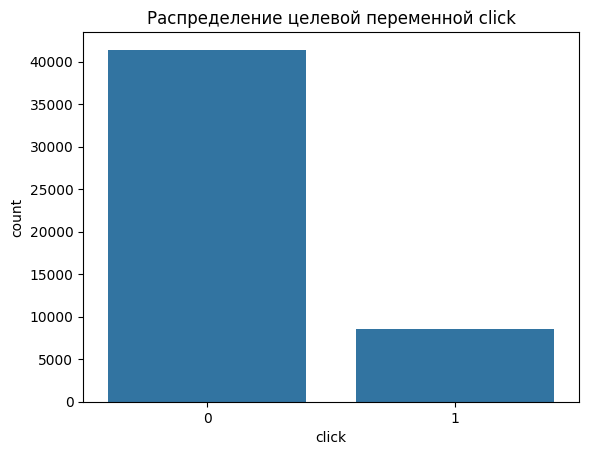

In [84]:
# Распределение целевой переменной churn
sns.countplot(x="click", data=df)
plt.title("Распределение целевой переменной click")
plt.show()

In [85]:
# Доля для click
shares = df['click'].value_counts(normalize=True)
print(shares)

click
0    0.82794
1    0.17206
Name: proportion, dtype: float64


**Промежуточные итоги**
* Наблюдается значительный дисбаланс классов. Лишь 17% кликов по банерам были совершены.

#### 2.3 Анализ признаков

* Признаки для удаления: id, device_ip, device_id, site_domain, app_domain. Причина: большое кол-во вариантов + неинформативность.
* hour - можно извлечь метку часа из метки для большей информативности распределения в течении суток.


**Категориальные признаки**
* id (float64) - **удалить**
* site_id (object)
* site_domain (object) - **удалить**
* site_category (object)
* app_id (object)
* app_domain (object) - **удалить**
* app_category (object)
* device_id (object) - **удалить**
* device_ip (object) - **удалить**
* device_model
* ml_feature_2 (object) 
* ml_feature_7 (object)


**Потенциально категориальные (Числовые) признаки**
* C1 (int64)
* banner_pos (int64)
* device_type (int64)
* device_conn_type (int64)
* hour (int64)

**Числовые признаки**
* click (int64) - **целевая переменная**
* C14 (int64)
* C15 (int64)
* C16 (int64)
* C17 (int64)
* C18 (int64)
* C19 (int64)
* C20 (int64)
* C21 (int64)
* ml_feature_1 (float64)
* ml_feature_3 (float64)
* ml_feature_4 (int64)
* ml_feature_5 (float64)
* ml_feature_6 (float64)
* ml_feature_8 (float64)
* ml_feature_9 (float64)
* ml_feature_10 (float64)

In [86]:
# Извлечение часа
df['hour_extracted'] = df['hour'] % 100

In [87]:
# Преобразование числовых в категориальные
cat_cols = ['C1', 'banner_pos', 'device_type', 'device_conn_type', 'hour_extracted']
df[cat_cols] = df[cat_cols].astype('category')
df = df

In [88]:
# Удаление неинформативных столбцов
cols_to_drop = ['id', 'device_id', 'device_ip', 'site_domain', 'app_domain', 'hour']
df = df.drop(columns=cols_to_drop)
df.shape

(50000, 29)

#### 2.4 Анализ пропущенных значений
* Пропуски NaN и альтернативные возможные варианты не обнаружены.

In [89]:
# Поиск возможных пропусков
empty_markers = ['', ' ', 'na', 'n/a', 'null', 'none', 'no', '-']

# количество по каждому столбцу
counts_empty = df.isin(empty_markers).sum()
print(counts_empty)

click               0
C1                  0
banner_pos          0
site_id             0
site_category       0
app_id              0
app_category        0
device_model        0
device_type         0
device_conn_type    0
C14                 0
C15                 0
C16                 0
C17                 0
C18                 0
C19                 0
C20                 0
C21                 0
ml_feature_1        0
ml_feature_2        0
ml_feature_3        0
ml_feature_4        0
ml_feature_5        0
ml_feature_6        0
ml_feature_7        0
ml_feature_8        0
ml_feature_9        0
ml_feature_10       0
hour_extracted      0
dtype: int64


**Промежуточные итоги**
* Пропуски не обнаружены

#### 2.5 Анализ категориальных признаков

In [90]:
# Категориальные столбцы
сols_cat = [
    'site_id', 
    'site_category', 
    'app_id', 
    'app_category', 
    'ml_feature_2', 
    'ml_feature_7', 
    'C1', 
    'banner_pos', 
    'device_model',
    'device_type', 
    'device_conn_type', 
    'hour_extracted'
]
print("Количество уникальных по категориальным столбцам:")
for col in сols_cat:
    print(f'{col}: {df[col].nunique()}')

Количество уникальных по категориальным столбцам:
site_id: 1160
site_category: 18
app_id: 976
app_category: 22
ml_feature_2: 5
ml_feature_7: 3
C1: 7
banner_pos: 7
device_model: 2521
device_type: 4
device_conn_type: 4
hour_extracted: 24


**Кодирование категориальных признаков**

**One-Hot Encoding** (менее 10 вариантов)
* ml_feature_2
* ml_feature_7
* C1
* banner_pos
* device_type
* device_conn_type

**Target Encoding**
* site_id
* site_category
* app_id
* app_category
* device_model
* hour_extracted

#### 2.6 Анализ выбросов и распределений

Анализ столбца C14
count    50000.000000
mean     18826.648680
std       4983.064178
min        375.000000
25%      16920.000000
50%      20346.000000
75%      21916.000000
max      24043.000000
Name: C14, dtype: float64


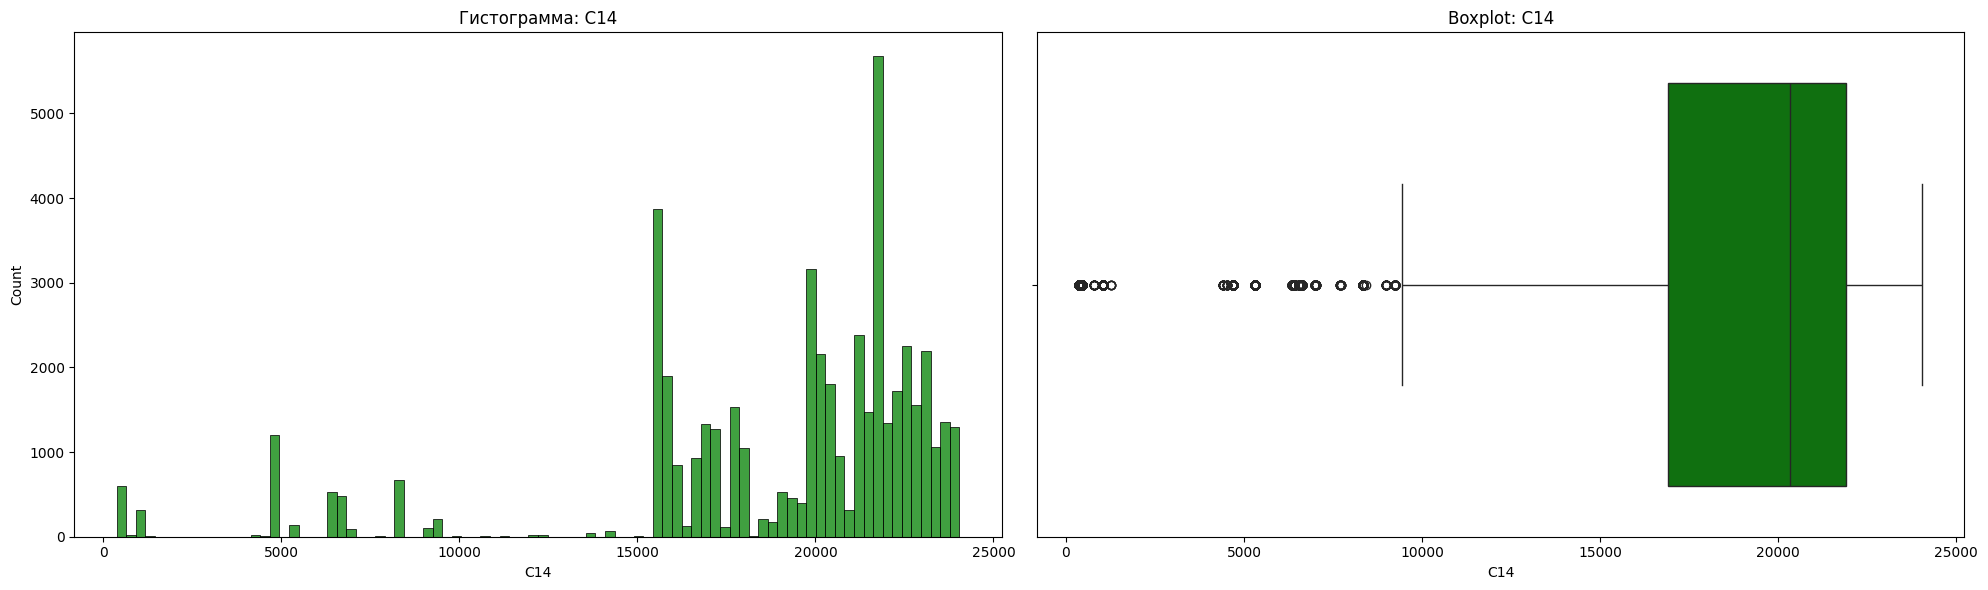

Анализ столбца C15
count    50000.00000
mean       318.86640
std         20.56153
min        120.00000
25%        320.00000
50%        320.00000
75%        320.00000
max       1024.00000
Name: C15, dtype: float64


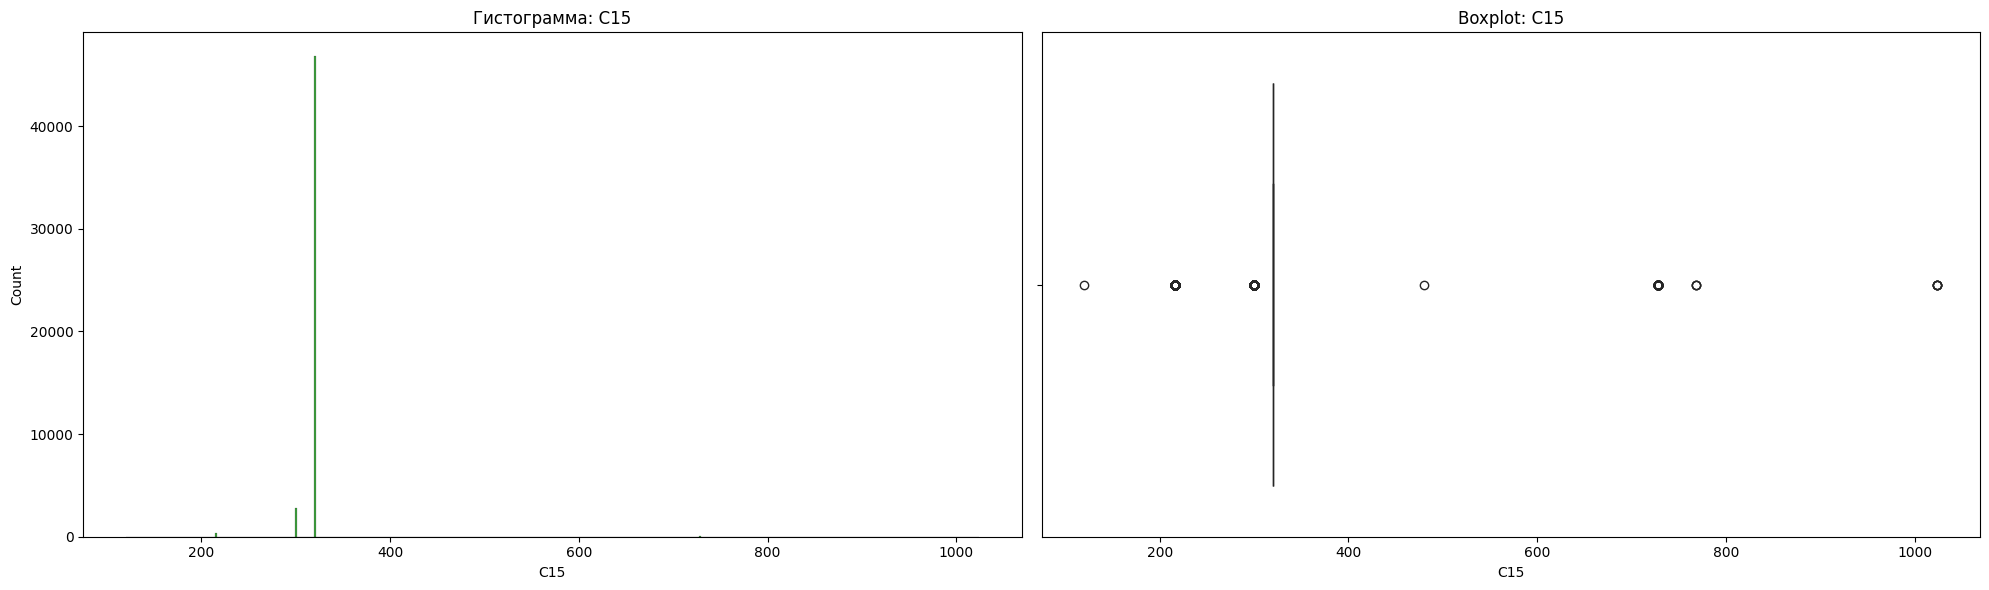

Анализ столбца C16
count    50000.000000
mean        59.692480
std         46.720842
min         20.000000
25%         50.000000
50%         50.000000
75%         50.000000
max       1024.000000
Name: C16, dtype: float64


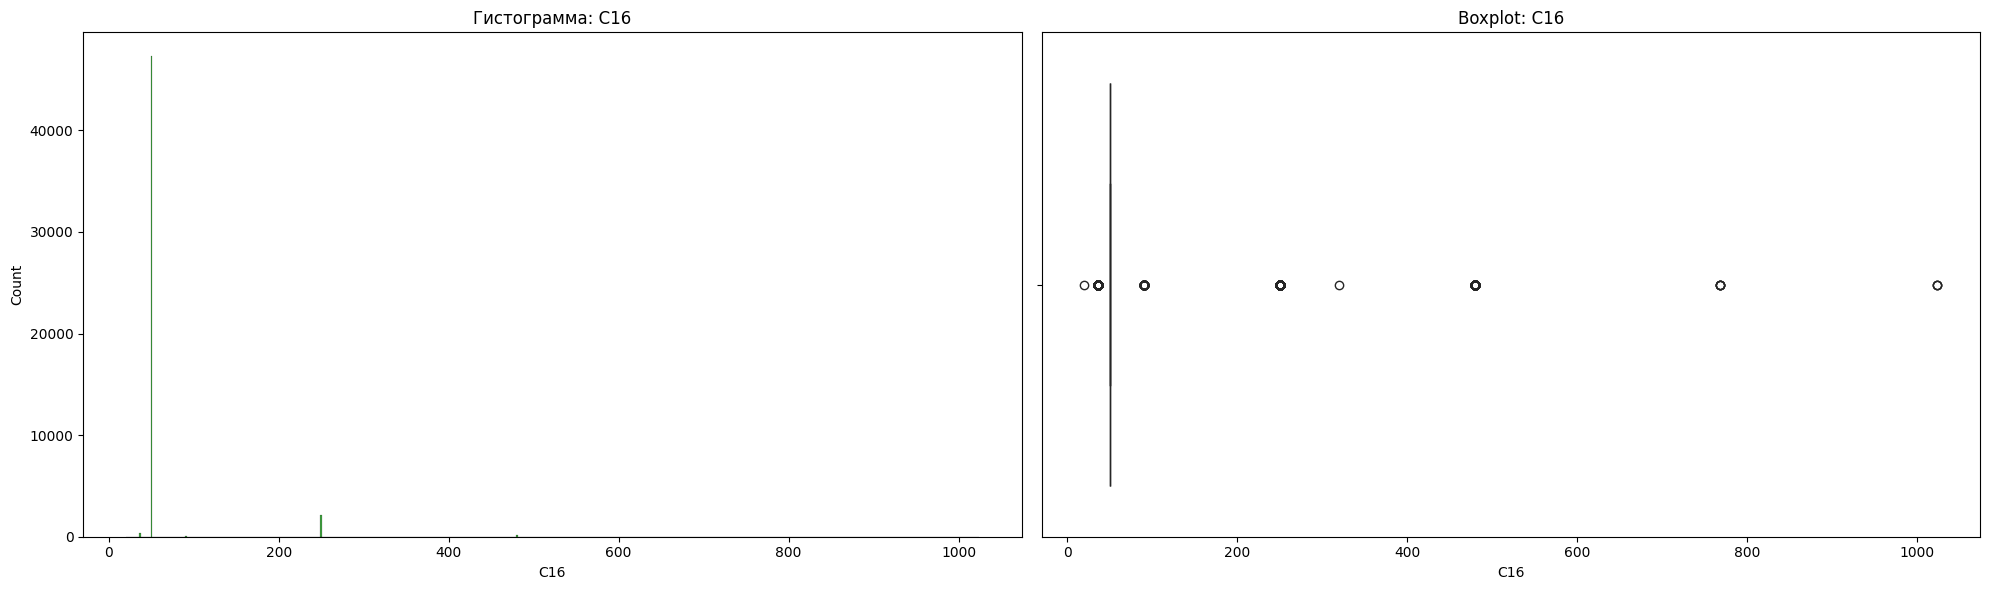

Анализ столбца C17
count    50000.000000
mean      2109.781020
std        612.963141
min        112.000000
25%       1823.000000
50%       2323.000000
75%       2526.000000
max       2757.000000
Name: C17, dtype: float64


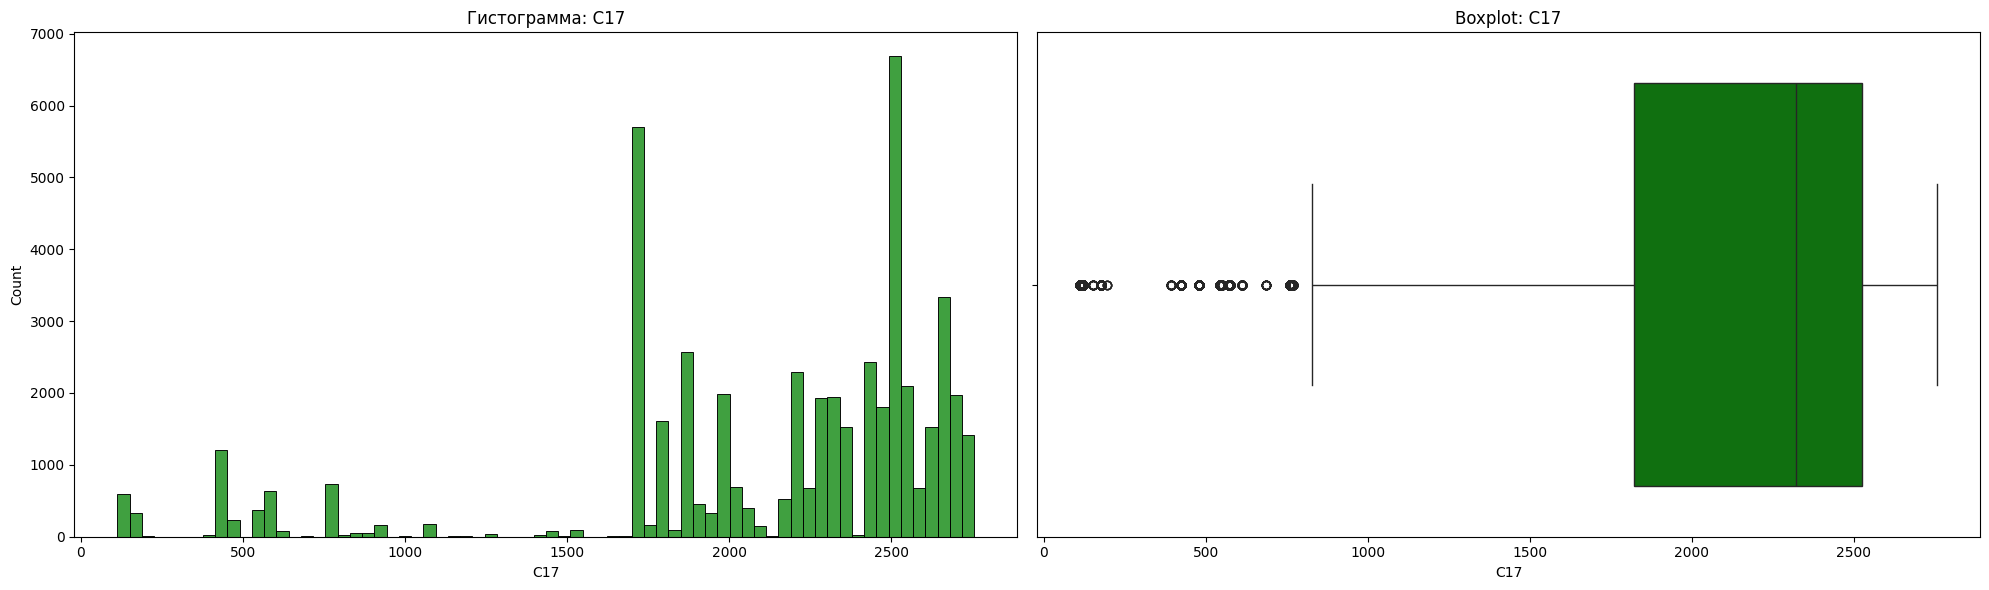

Анализ столбца C18
count    50000.000000
mean         1.428100
std          1.327413
min          0.000000
25%          0.000000
50%          2.000000
75%          3.000000
max          3.000000
Name: C18, dtype: float64


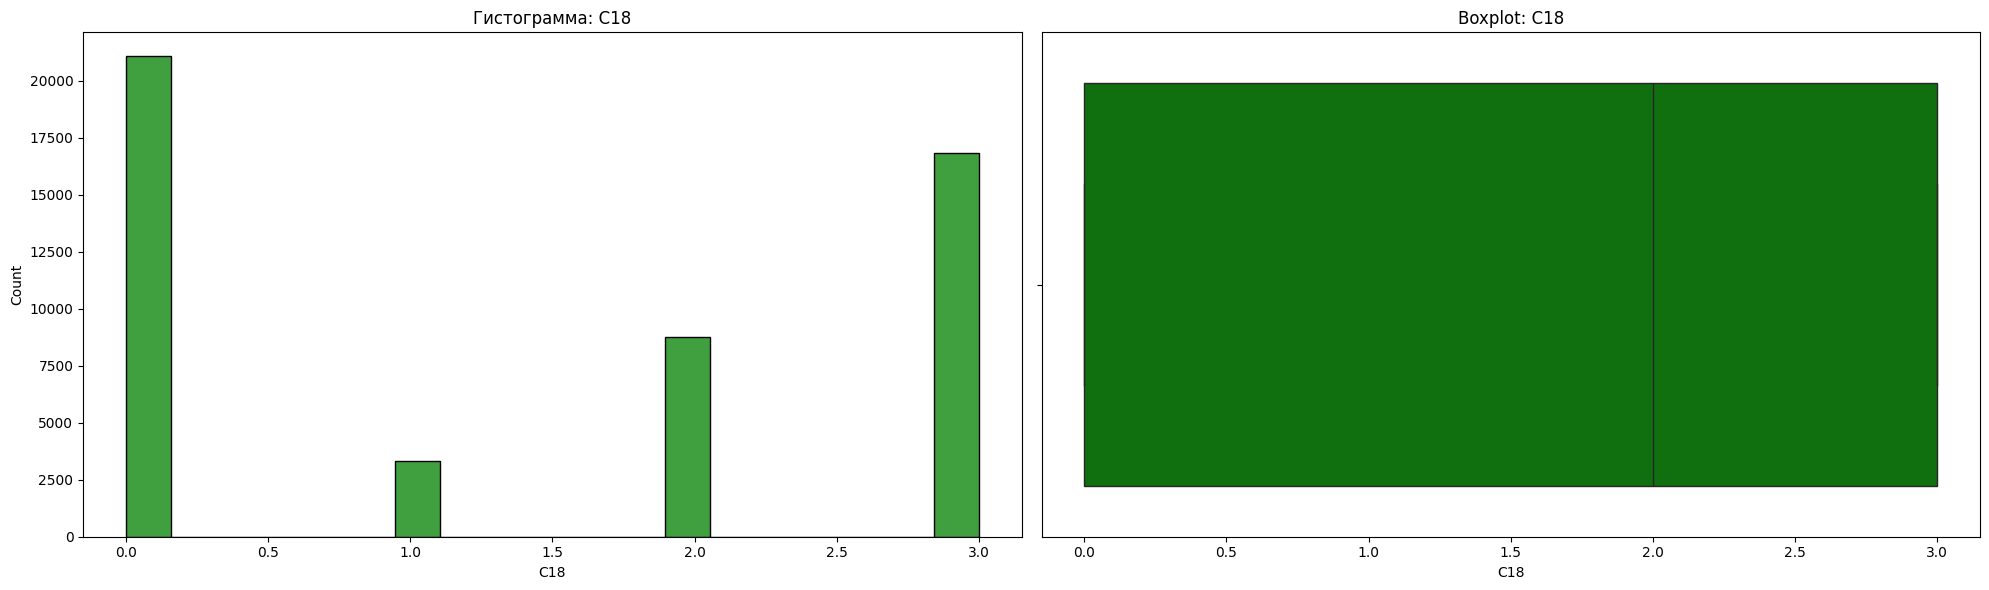

Анализ столбца C19
count    50000.000000
mean       227.703800
std        351.592108
min         33.000000
25%         35.000000
50%         39.000000
75%        171.000000
max       1839.000000
Name: C19, dtype: float64


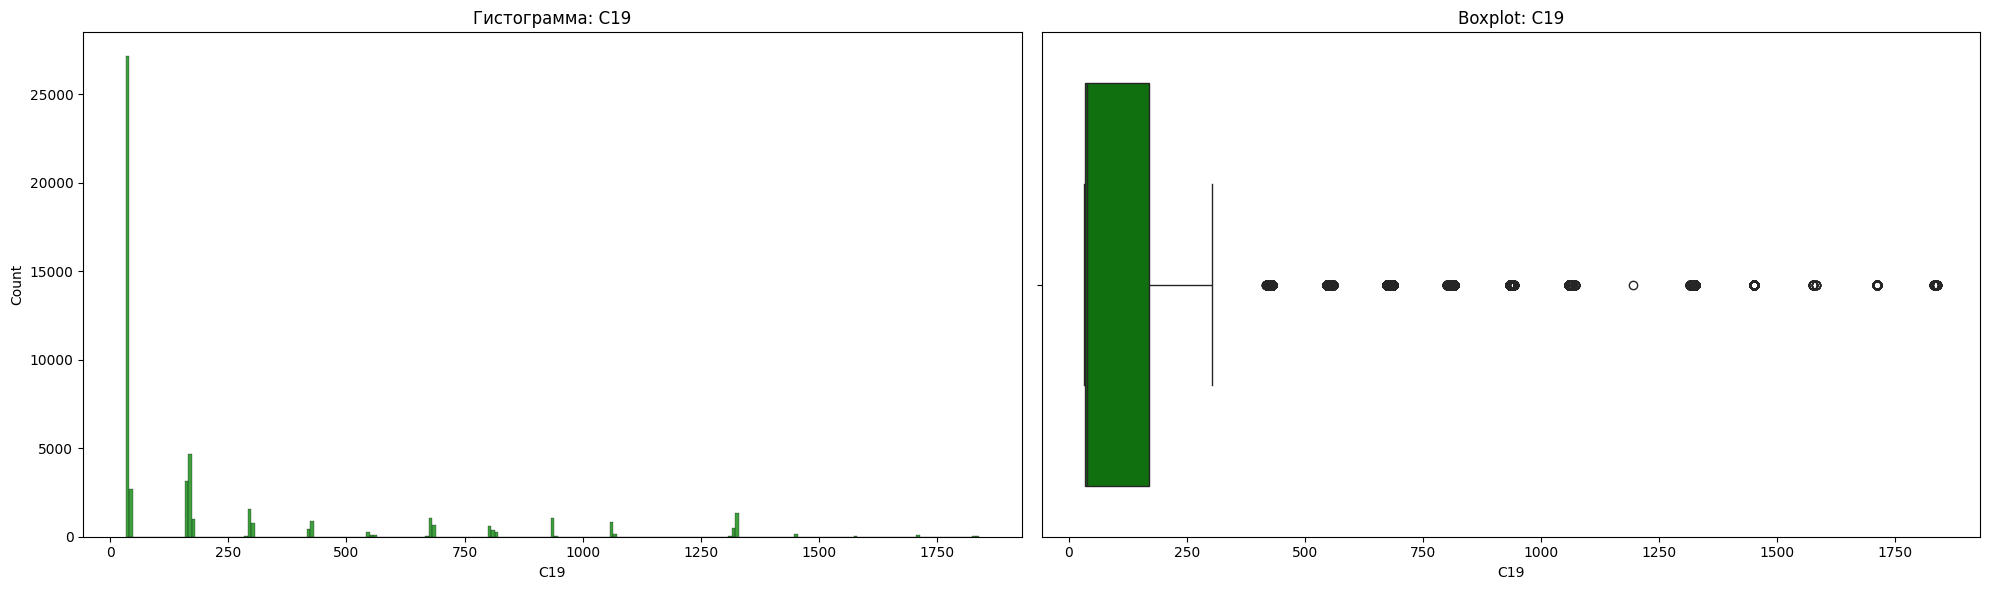

Анализ столбца C20
count     50000.000000
mean      53173.383240
std       49960.181871
min          -1.000000
25%          -1.000000
50%      100049.000000
75%      100094.000000
max      100248.000000
Name: C20, dtype: float64


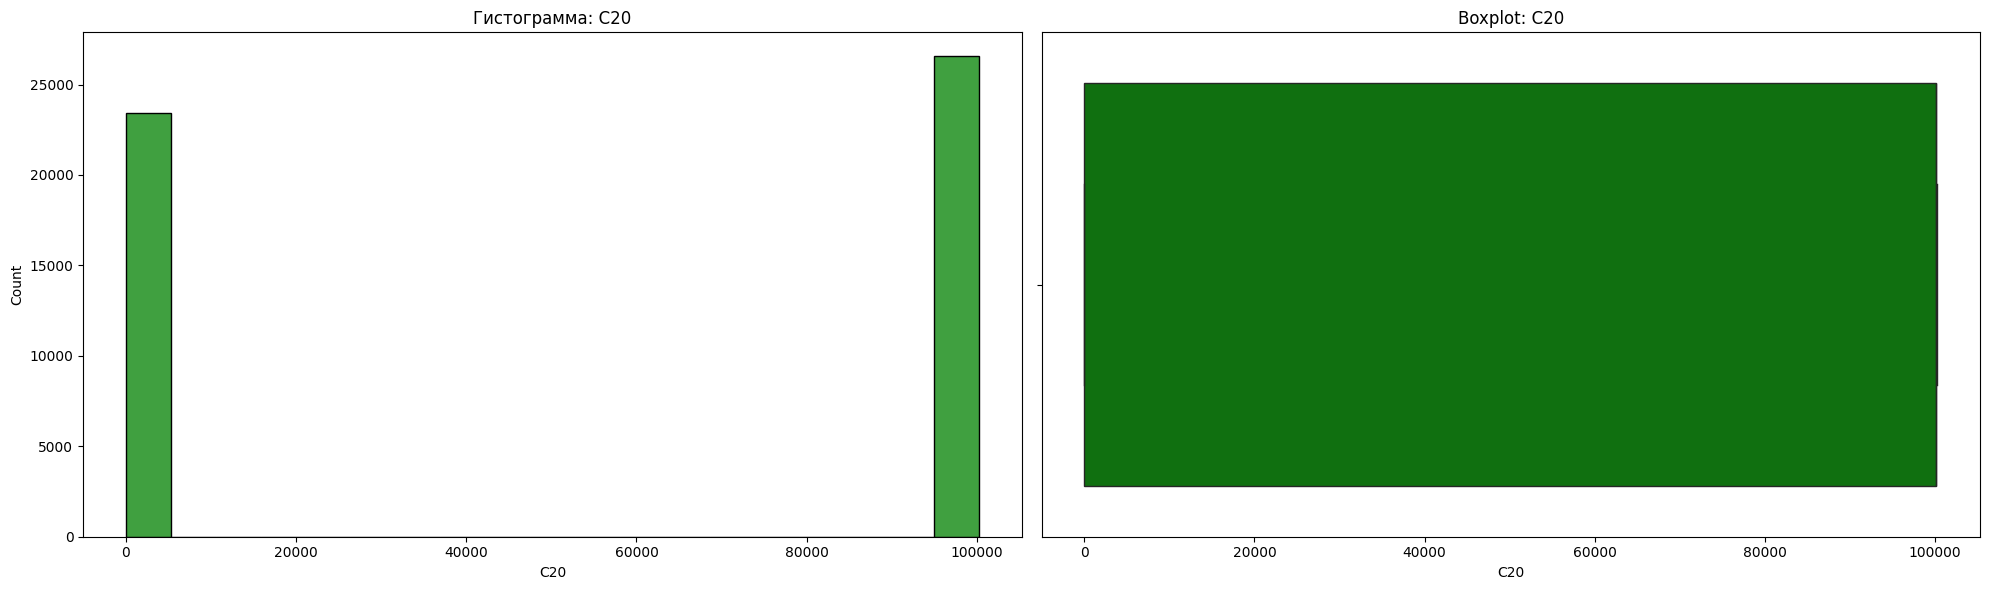

Анализ столбца C21
count    50000.000000
mean        83.685180
std         70.539513
min         13.000000
25%         23.000000
50%         61.000000
75%        108.000000
max        255.000000
Name: C21, dtype: float64


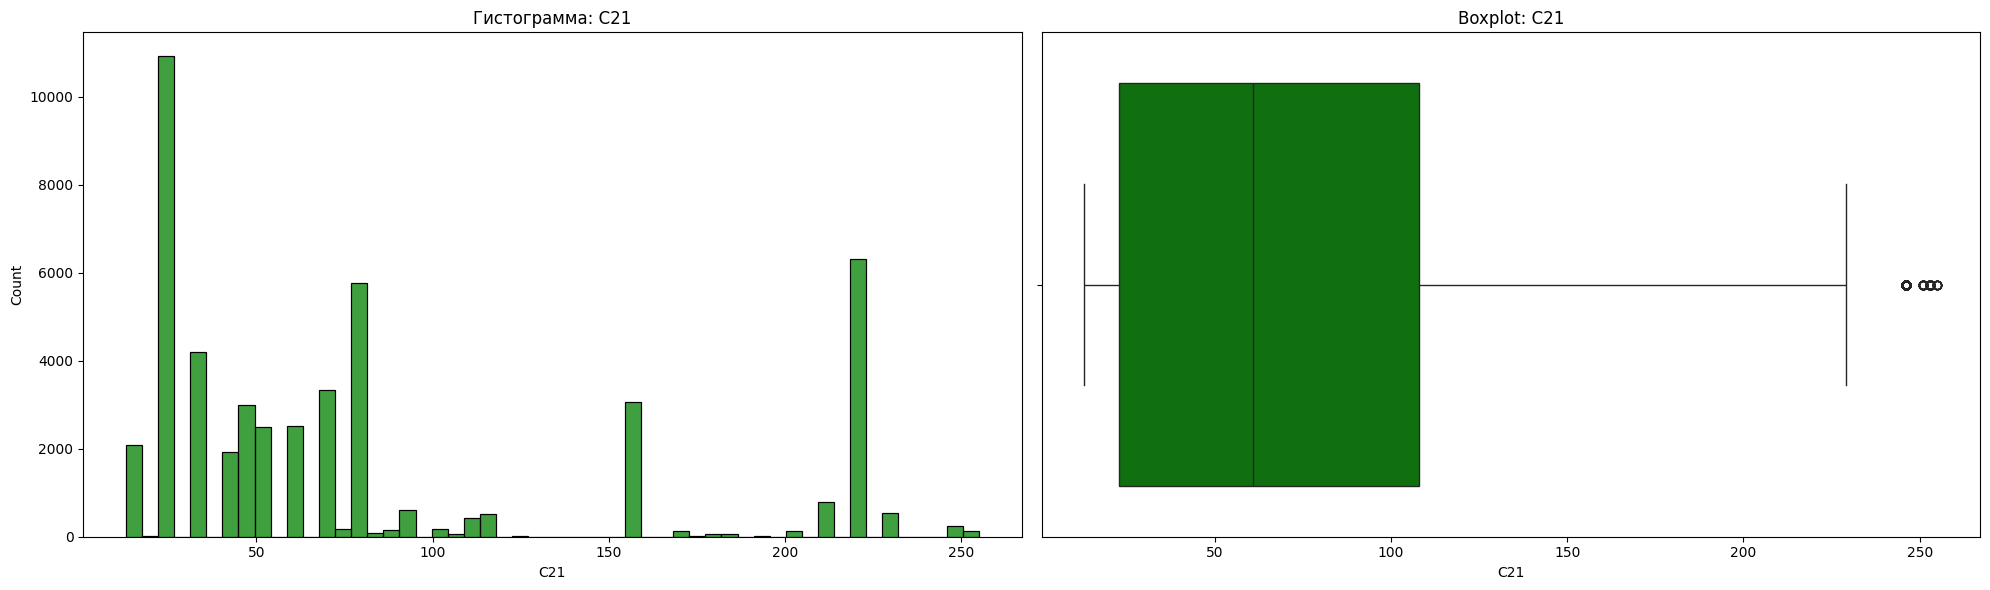

Анализ столбца ml_feature_1
count    50000.000000
mean        -0.002445
std          1.000280
min         -4.631262
25%         -0.677784
50%         -0.003776
75%          0.673534
max          3.793828
Name: ml_feature_1, dtype: float64


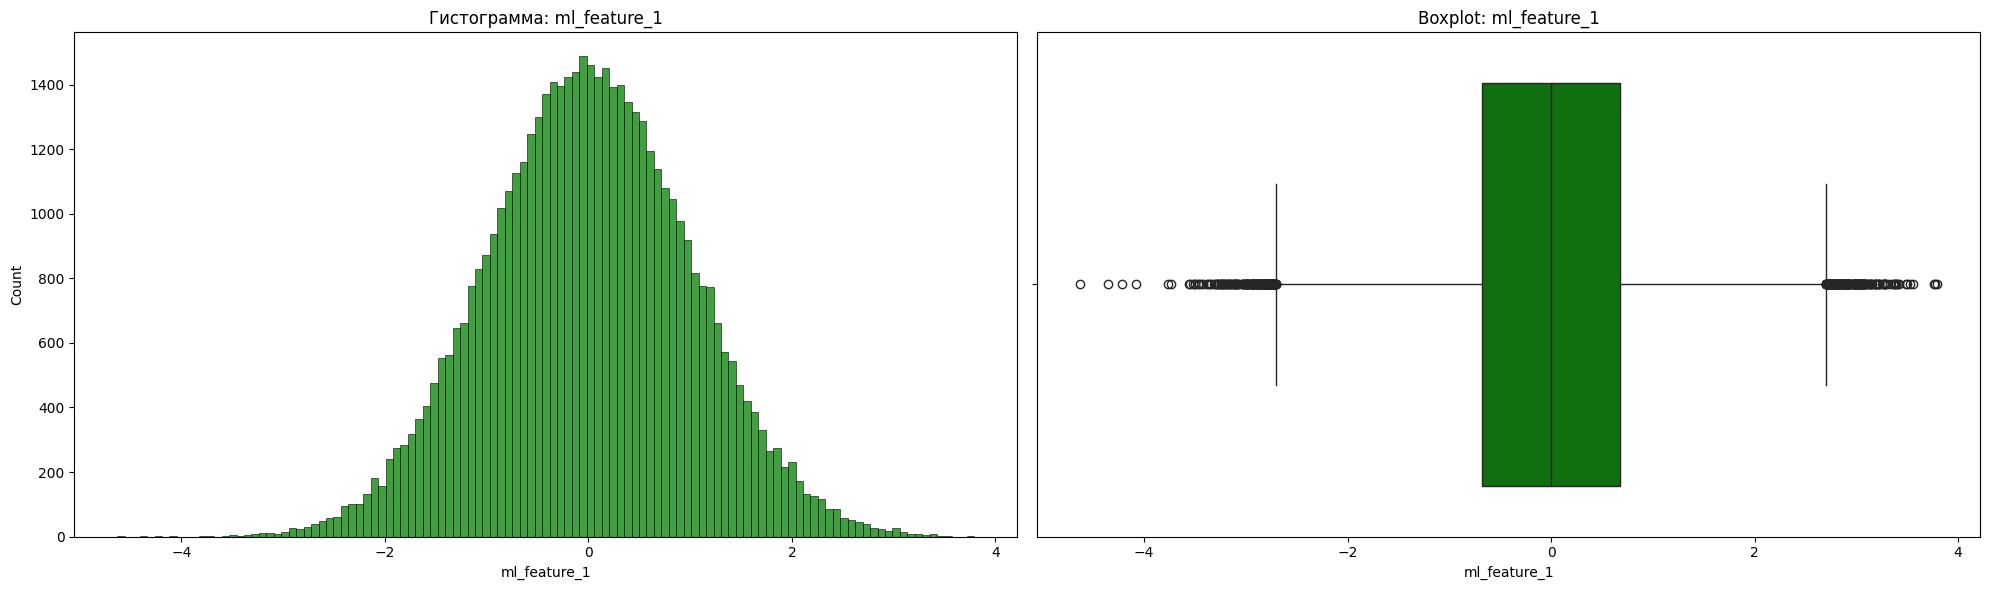

Анализ столбца ml_feature_3
count    50000.000000
mean        -0.036381
std          5.792335
min         -9.999742
25%         -5.059555
50%         -0.056155
75%          4.985939
max          9.999975
Name: ml_feature_3, dtype: float64


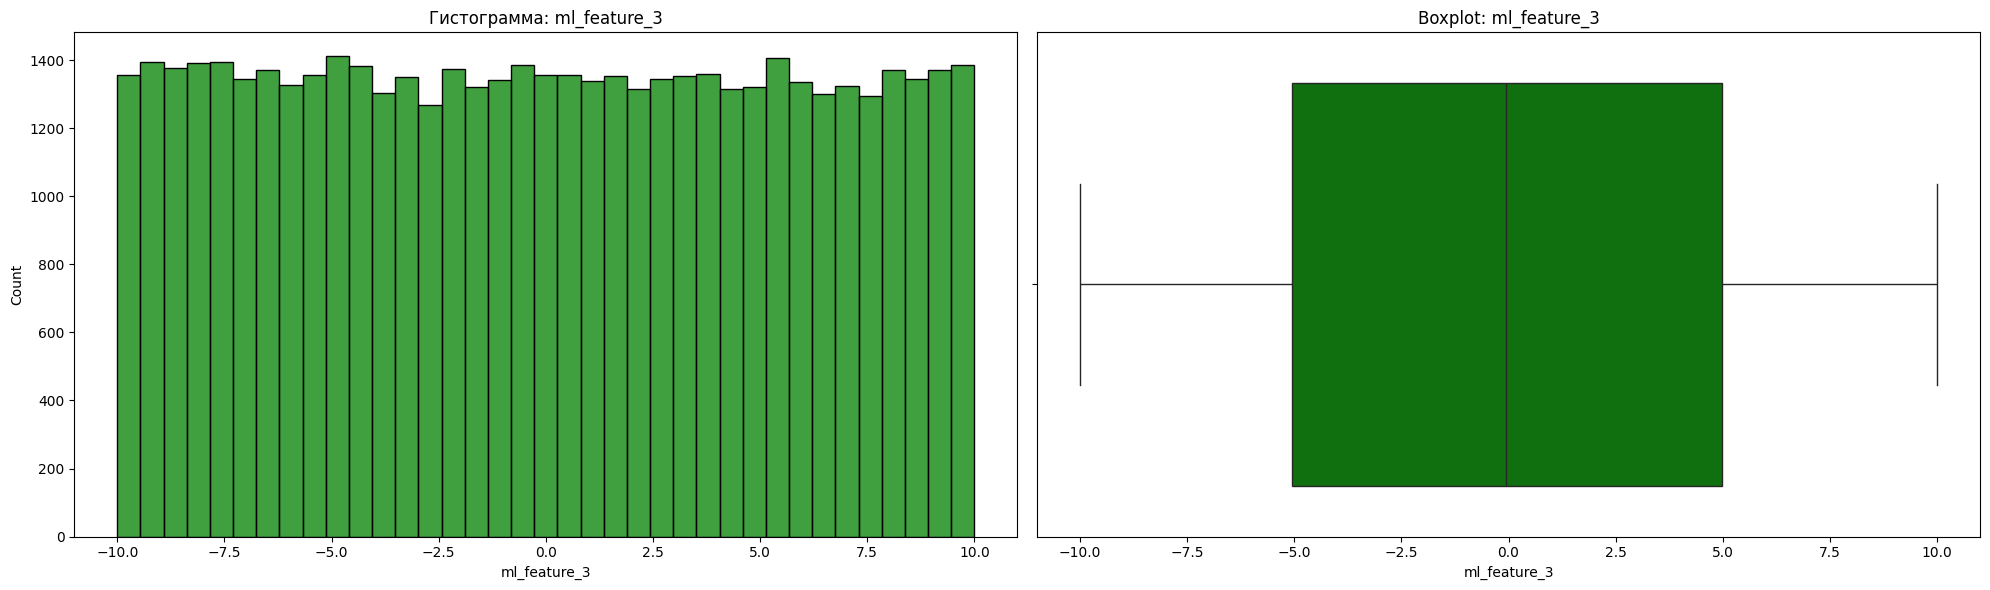

Анализ столбца ml_feature_4
count    50000.000000
mean         0.498040
std          0.500001
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          1.000000
Name: ml_feature_4, dtype: float64


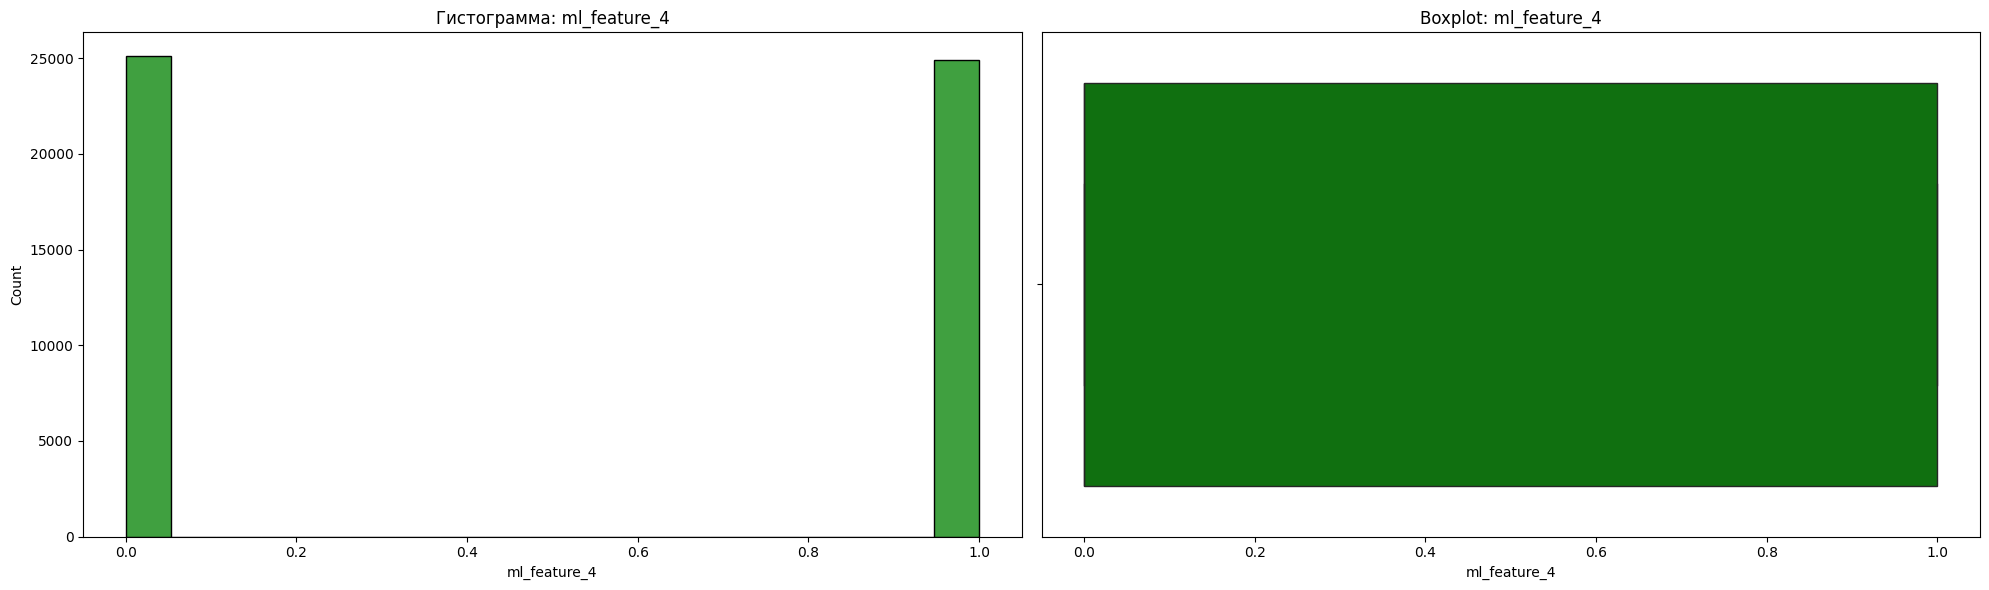

Анализ столбца ml_feature_5
count    50000.000000
mean         0.034729
std          1.002116
min         -4.631853
25%         -0.639829
50%          0.028112
75%          0.707594
max          4.230623
Name: ml_feature_5, dtype: float64


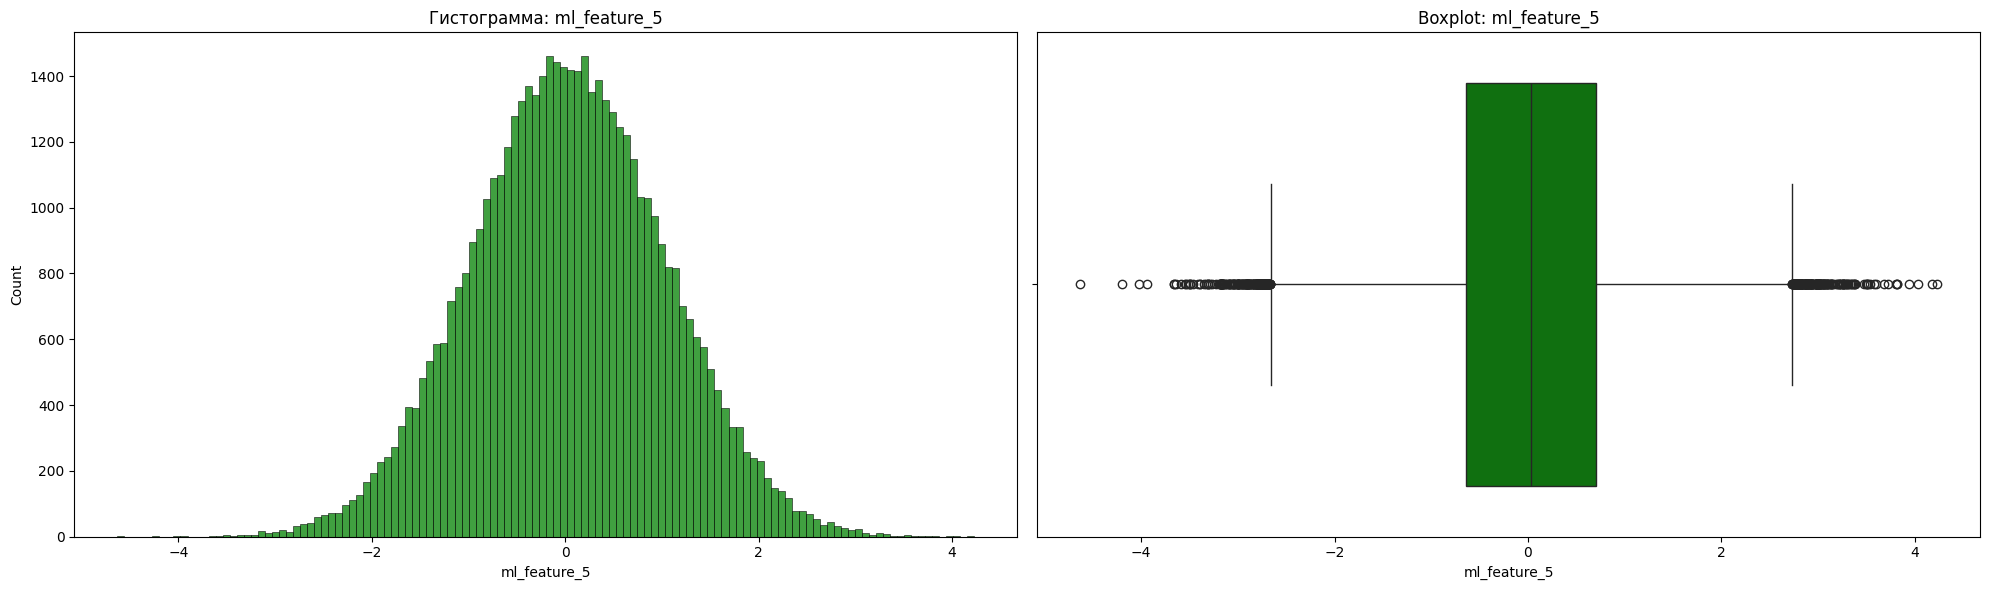

Анализ столбца ml_feature_6
count    50000.000000
mean         0.022948
std          0.656690
min         -1.000000
25%         -0.579775
50%          0.037786
75%          0.637131
max          1.000000
Name: ml_feature_6, dtype: float64


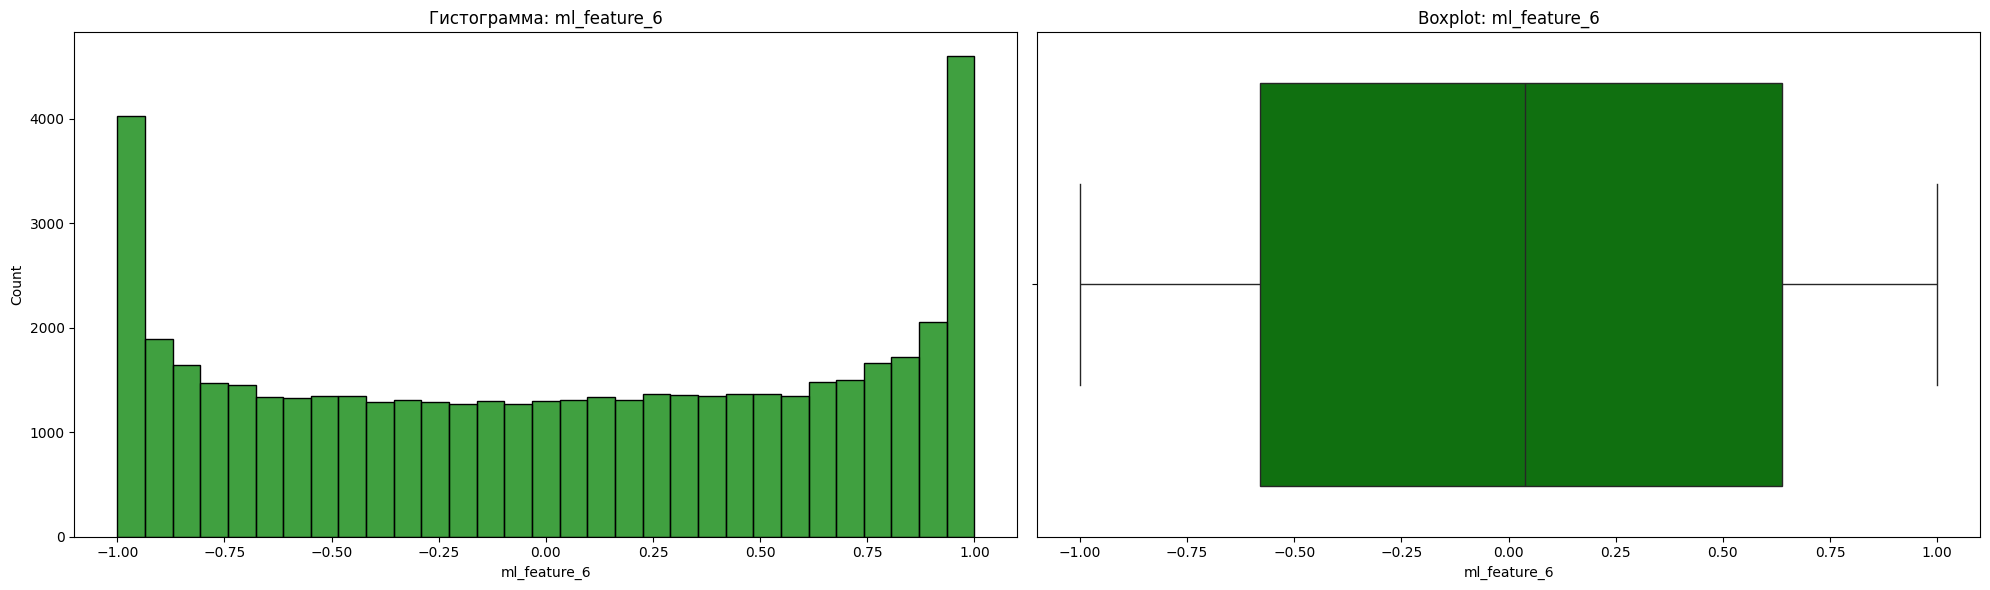

Анализ столбца ml_feature_8
count    50000.000000
mean         0.025465
std          0.578026
min         -0.999965
25%         -0.470627
50%          0.027348
75%          0.521117
max          1.119858
Name: ml_feature_8, dtype: float64


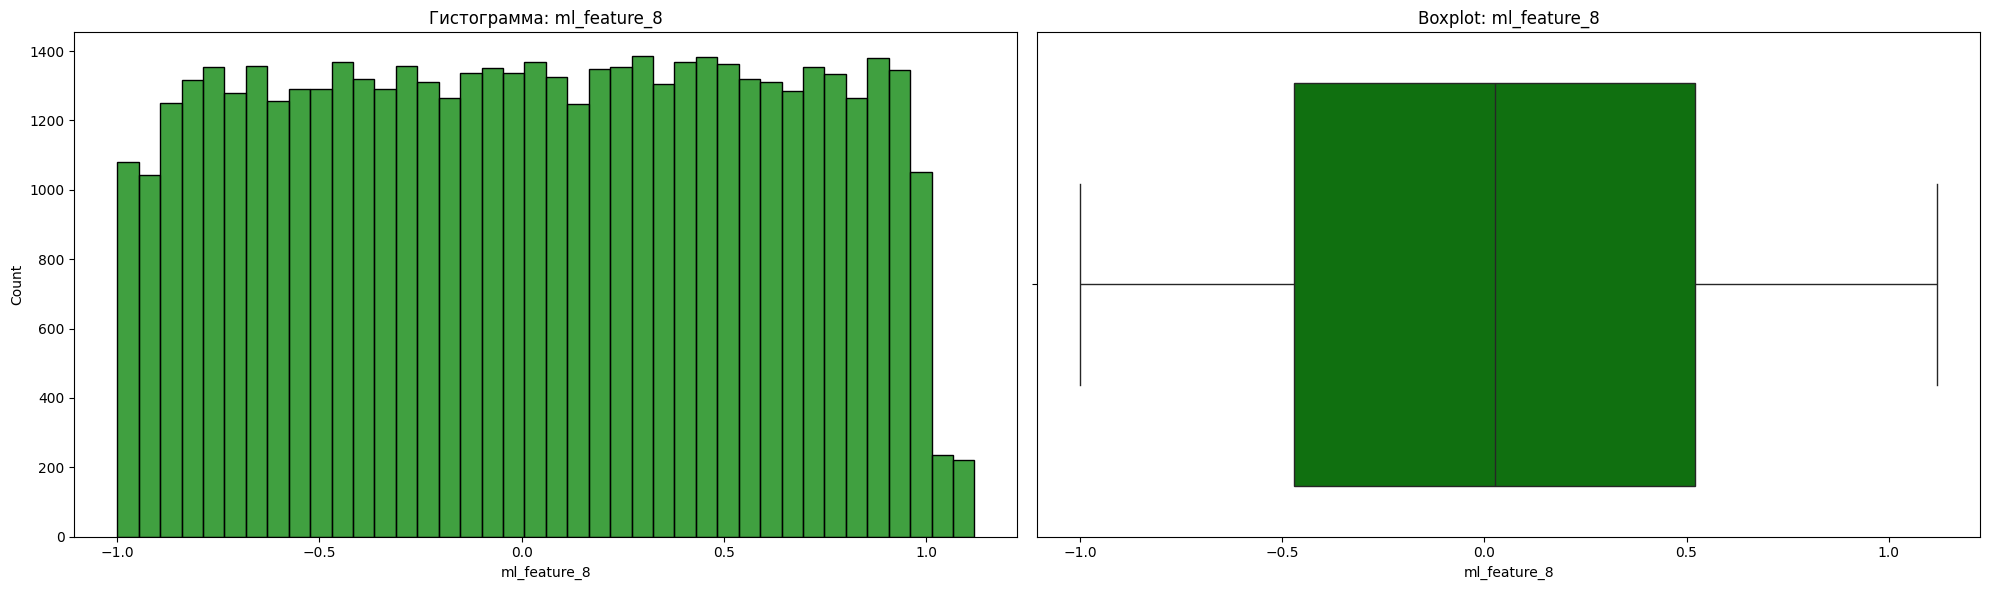

Анализ столбца ml_feature_9
count    50000.000000
mean         0.035361
std          0.505034
min         -2.147526
25%         -0.304077
50%          0.035985
75%          0.374152
max          2.120786
Name: ml_feature_9, dtype: float64


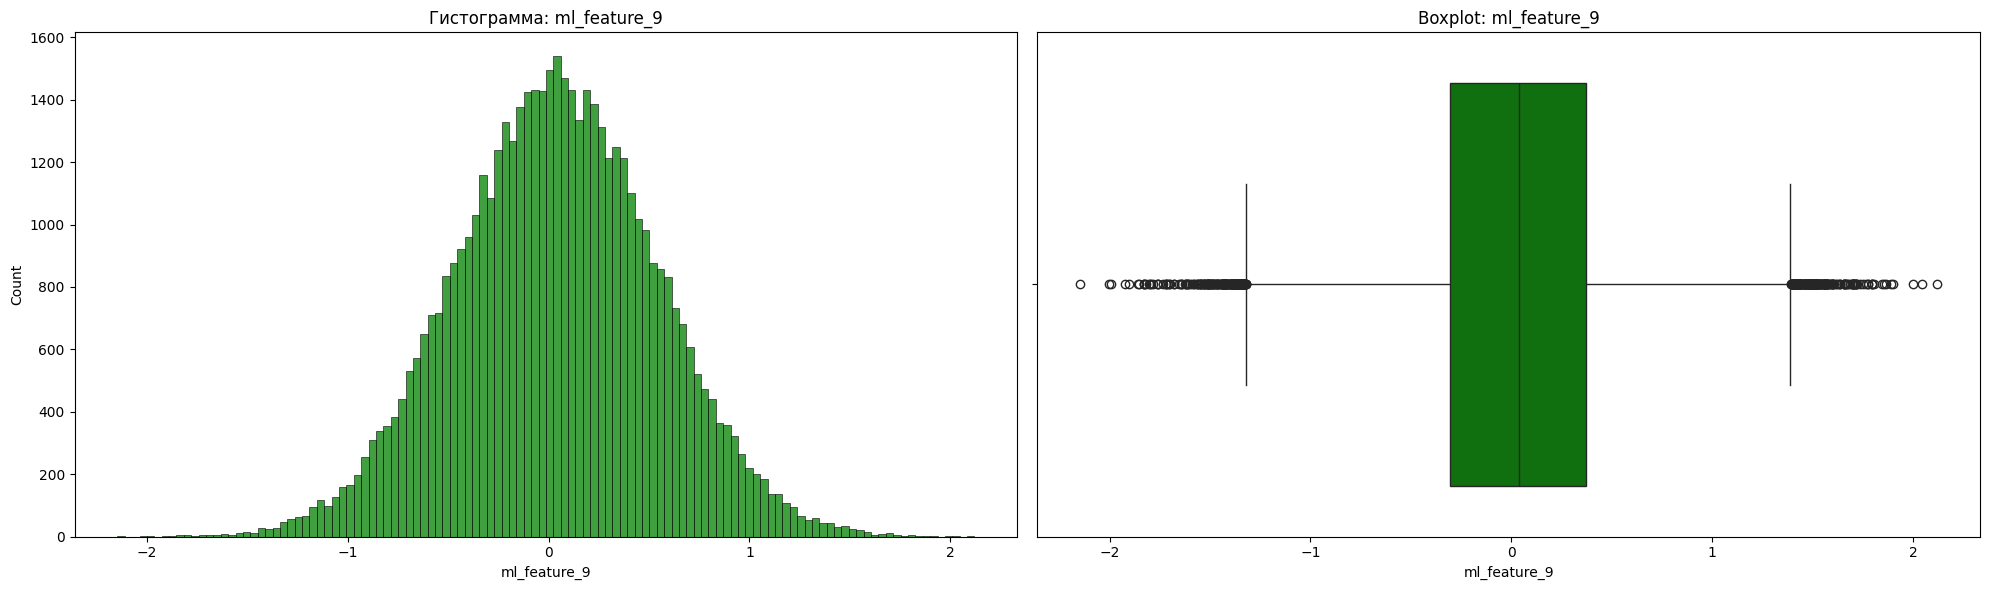

Анализ столбца ml_feature_10
count    50000.000000
mean         0.020226
std          0.303309
min         -1.287965
25%         -0.182386
50%          0.018930
75%          0.224080
max          1.202300
Name: ml_feature_10, dtype: float64


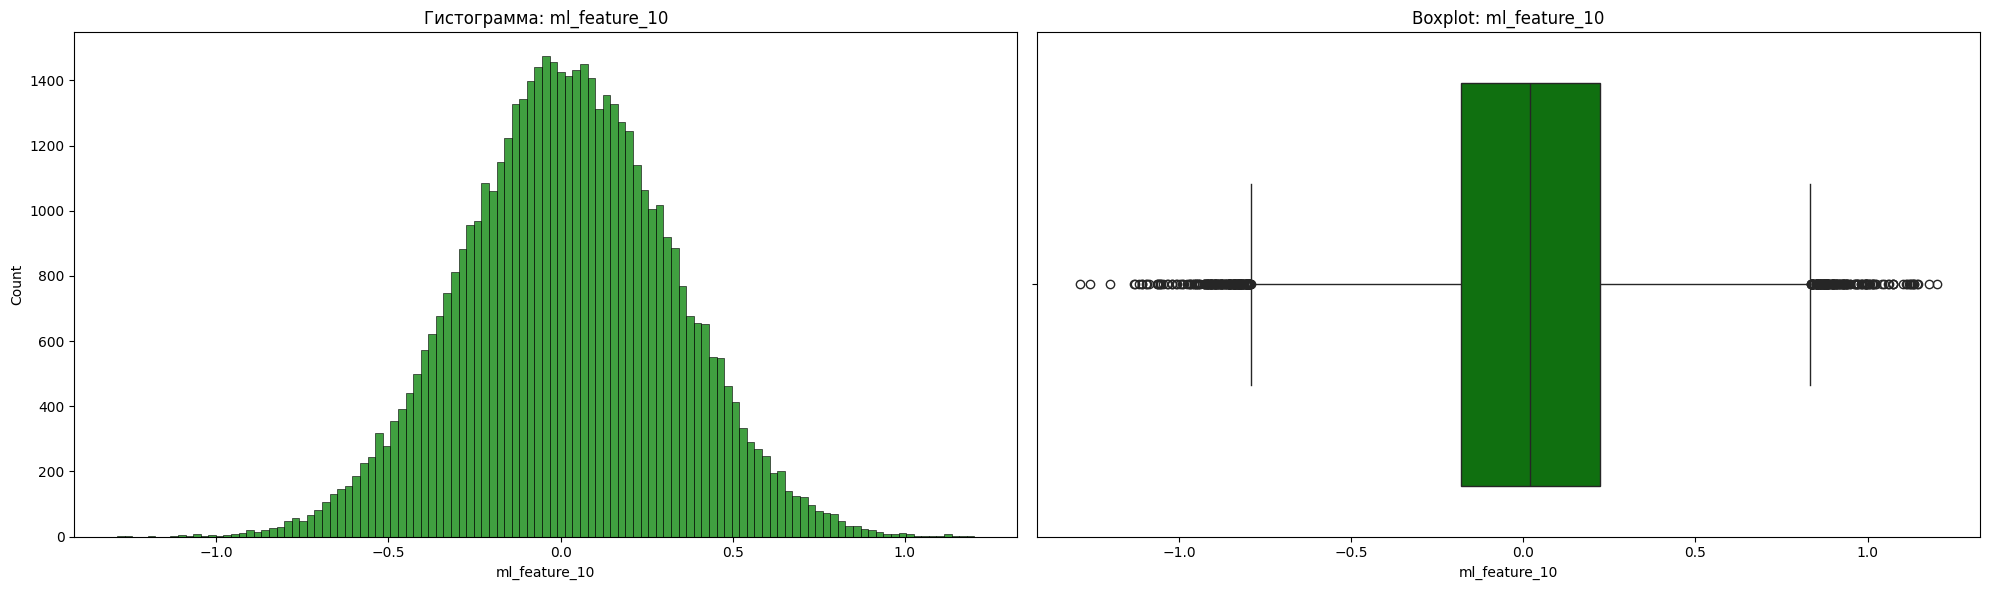

In [91]:
# Числовые столбцы
numeric_cols = [
    'C14', 
    'C15',   
    'C16', 
    'C17', 
    'C18', 
    'C19', 
    'C20', 
    'C21', 
    'ml_feature_1', 
    'ml_feature_3', 
    'ml_feature_4', 
    'ml_feature_5', 
    'ml_feature_6', 
    'ml_feature_8', 
    'ml_feature_9', 
    'ml_feature_10'
]

# Гистограммы для числовых
for col in numeric_cols:
    print(f'Анализ столбца {col}')
    print(df.describe()[col])
    fig, axes = plt.subplots(1, 2, figsize=(20, 6))

    sns.histplot(df[col].dropna(), ax=axes[0], color='green')
    axes[0].set_title(f'Гистограмма: {col}')

    sns.boxplot(x=df[col].dropna(), ax=axes[1], color='green')
    axes[1].set_title(f'Boxplot: {col}')
    plt.tight_layout()
    plt.show()


In [92]:
# Считаем выбросы
out_of_iqr = {}

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    upper_border = q3 + 1.5 * iqr
    count_upper = (df[col] > upper_border).sum()
    out_of_iqr[col] = count_upper

out_of_iqr = pd.DataFrame(list(out_of_iqr.items()),
                                columns=['column', 'out_of_iqr'])
print("*****Выбросы*****")
print(out_of_iqr)

*****Выбросы*****
           column  out_of_iqr
0             C14           0
1             C15          87
2             C16        2345
3             C17           0
4             C18           0
5             C19        9015
6             C20           0
7             C21         379
8    ml_feature_1         178
9    ml_feature_3           0
10   ml_feature_4           0
11   ml_feature_5         181
12   ml_feature_6           0
13   ml_feature_8           0
14   ml_feature_9         202
15  ml_feature_10         160


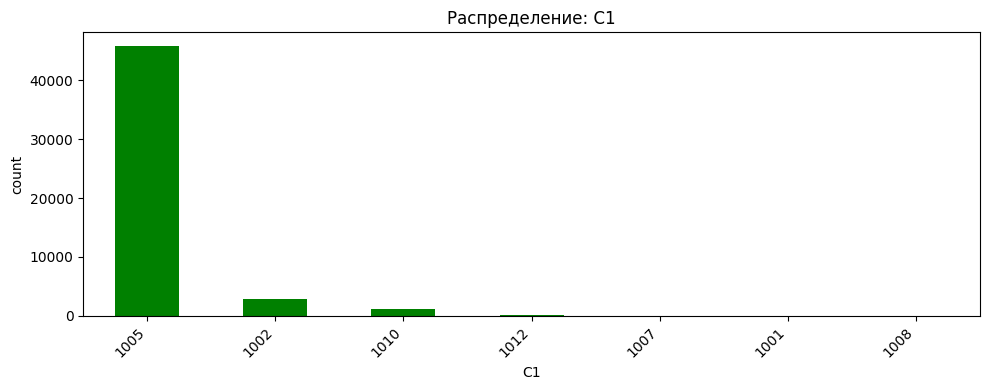

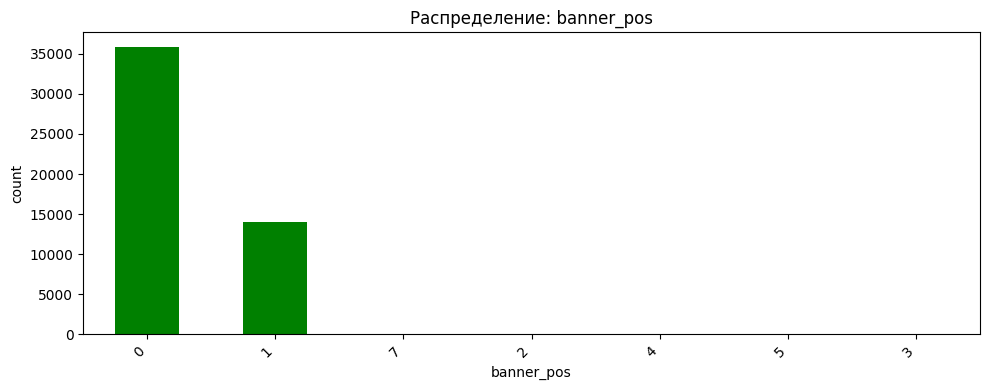

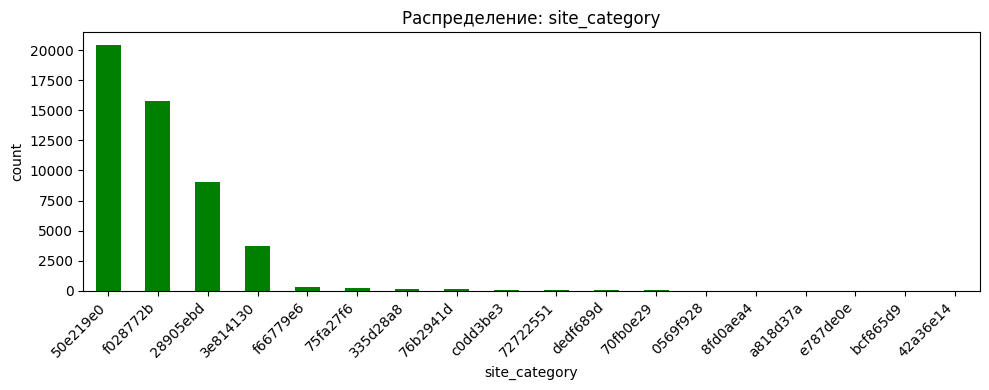

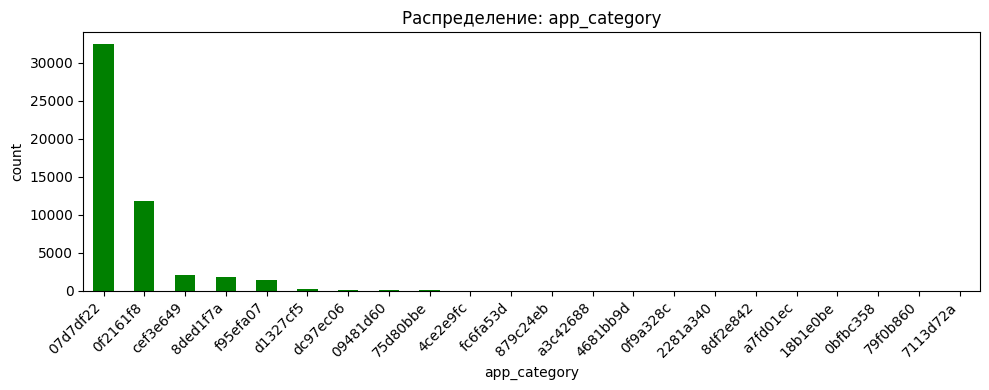

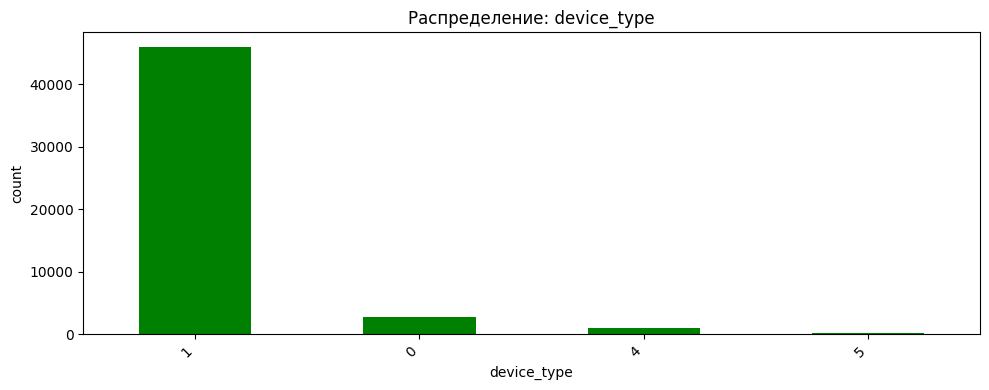

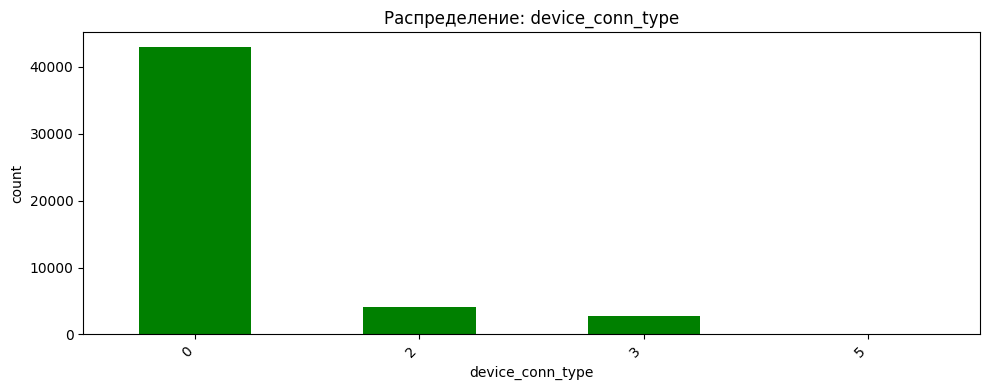

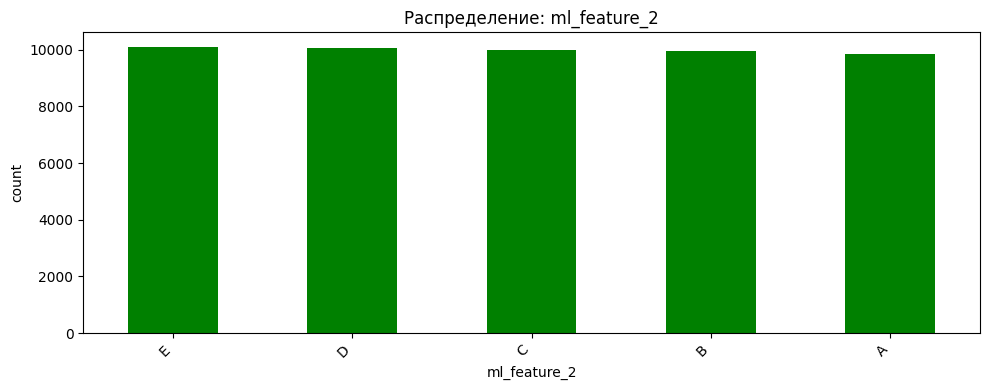

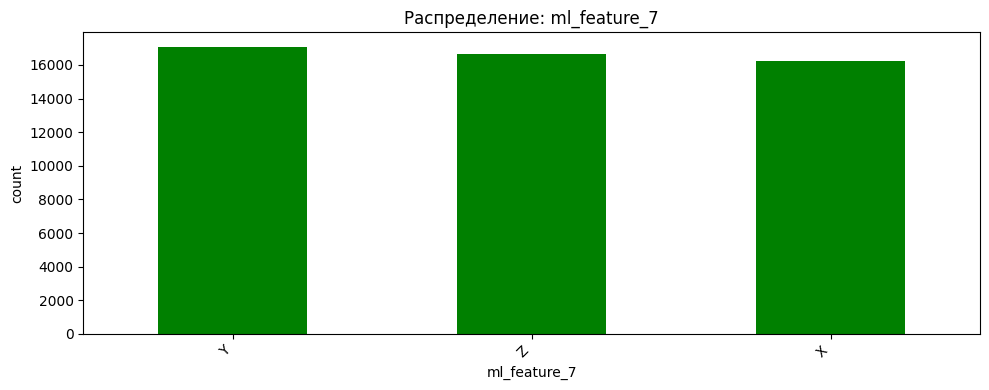

In [93]:
# Категориальные столбцы
categorical_cols = [
    'C1', 
    'banner_pos', 
    'site_category', 
    'app_category', 
    'device_type', 
    'device_conn_type', 
    'ml_feature_2', 
    'ml_feature_7'
]

# Гистограммы для категориальных    
for col in categorical_cols:
    plt.figure(figsize=(10, 4))
    df[col].value_counts().plot(kind='bar', color='green')
    plt.title(f'Распределение: {col}')
    plt.ylabel('count')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

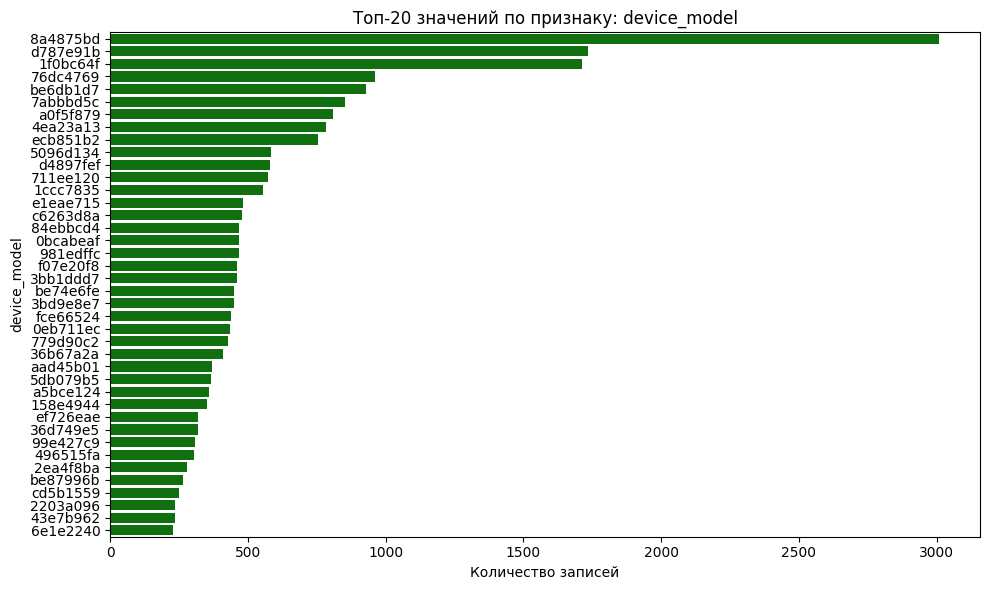

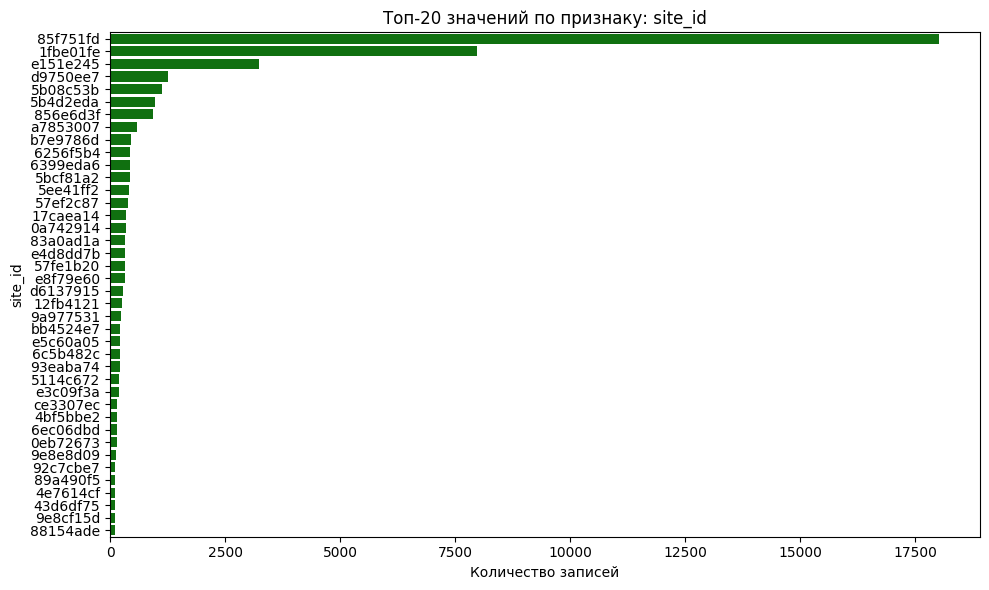

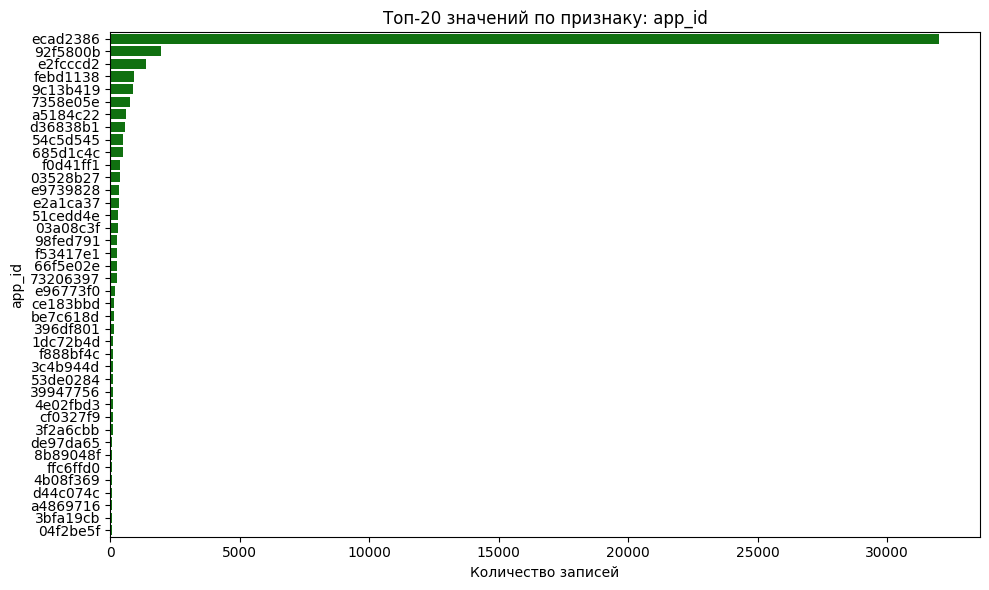

In [94]:
# Категориальные столбцы с большим количеством категорий
cols = ['device_model', 'site_id', 'app_id']
for col in cols:
    # топ-40 самых частых значений
    top_vals = df[col].value_counts().head(40)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x=top_vals.values, y=top_vals.index, color='green')
    plt.title(f'Топ-20 значений по признаку: {col}')
    plt.xlabel('Количество записей')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

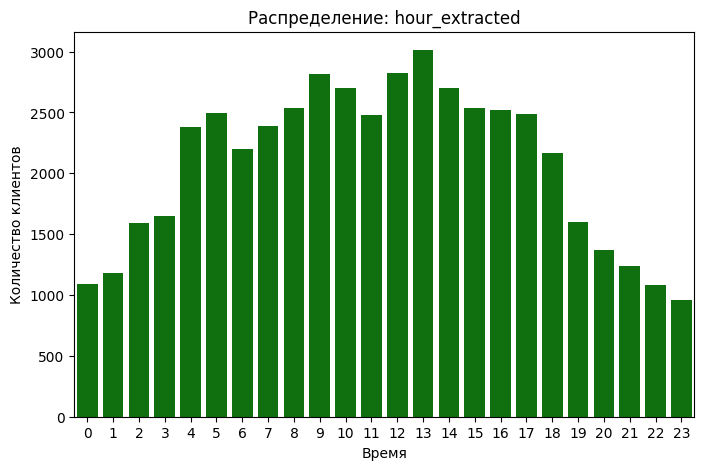

In [95]:
# Распределение активности по часам
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x='hour_extracted',
    color='green'
)
plt.title('Распределение: hour_extracted')
plt.xlabel('Время')
plt.ylabel('Количество клиентов')
plt.show()

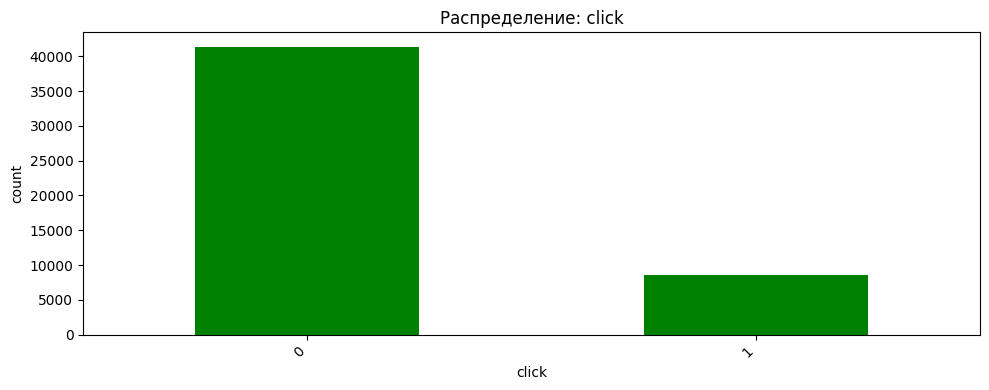

In [96]:
# Бинарные столбцы
binary_cols = [
    'click'
]
# Гистограммы для бинарных    
for col in binary_cols:
    plt.figure(figsize=(10, 4))
    df[col].value_counts().plot(kind='bar', color='green')
    plt.title(f'Распределение: {col}')
    plt.ylabel('count')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()  


**Анализ выбросов и распределений. Промежуточные итоги**
* Числовые
    * 'C14' — Имеются выбросы. Данные несимметричны. 
    * 'C15' — Имеются выбросы. Данные преимущественно представлены одним значением.  
    * 'C16' — Имеются выбросы. Данные преимущественно представлены одним значением.  
    * 'C17' — Имеются выбросы. Данные несимметричны. 
    * 'C18' — Выбросов нет. Данные представлены всего 4 значениями.  
    * 'C19' — Имеются выбросы. Данные несимметричны. 
    * 'C20' — Основная часть данных сконцентрирована вокруг значений более 100000, но 25% значений представлены как -1. Возможно это означает отсутствие данных и есть смысл заменить на mean.  
    * 'C21' — Имеются выбросы. Данные несимметричны.  
    * 'ml_feature_1' — Имеются выбросы. Данные симметричны  
    * 'ml_feature_3' — Выбросов нет. Медиана сконцентрирована около 0.
    * 'ml_feature_4'— Выбросов нет. Данные распределены поровну между 0 и 1. 
    * 'ml_feature_5' — Имеются выбросы. Данные симметричны   
    * 'ml_feature_6' — Выбросов нет. Медиана сконцентрирована около 0. 
    * 'ml_feature_8' — Выбросов нет. Медиана сконцентрирована около 0. 
    * 'ml_feature_9' — Имеются выбросы. Данные симметричны  
    * 'ml_feature_10' — Имеются выбросы. Данные симметричны 
* Категориальные
    * 'C1' — Распределение между категориями неравномерно с явным доминированием категории 1005. 
    * 'banner_pos' — Распределение между категориями неравномерно с явным доминированием двух категорий 0 и 1. 
    * 'site_category' — Распределение между категориями неравномерно с явным доминированием 4х категорий с значительным падением остальных категорий. 
    * 'app_category'— Распределение между категориями неравномерно с явным доминированием 2х категорий с значительным падением остальных категорий. 
    * 'device_type' — Распределение между категориями неравномерно с явным доминированием категории 1. 
    * 'device_conn_type'— Распределение между категориями неравномерно с явным доминированием категории 0. 
    * 'ml_feature_2' — распределение между категориями равномерно. 
    * 'ml_feature_7'— распределение между категориями равномерно. 
    * 'device_model' — большое количество категорий (>2500). Распределение неравномерно
    * 'site_id'— большое количество категорий (>1100). Распределение неравномерно/ Явное доминирование 3х категорий
    * 'app_id'— большое количество категорий (>950). Распределение неравномерно/ Явное доминирование 1 категории
    * 'hour_extracted' — нормальное распределение с учетом потенциальной активности пользоваетелей в течении суток.

#### 2.7 Корреляции

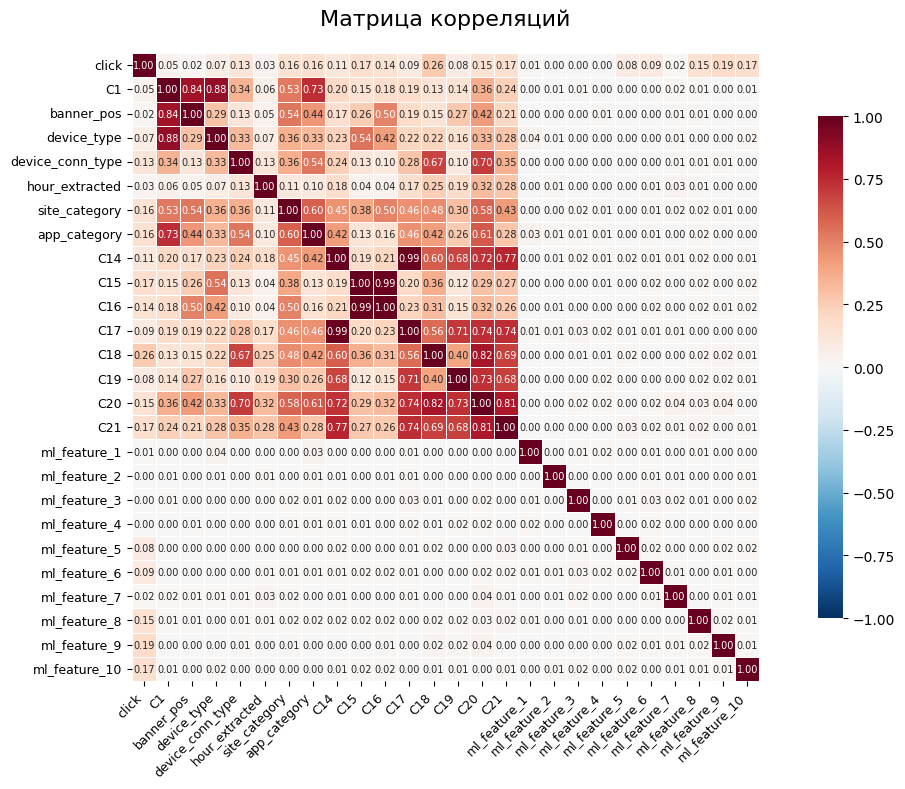

In [97]:
# Phik-корреляция
phik_cols = [
    'click', 'C1', 'banner_pos', 'device_type', 'device_conn_type',
    'hour_extracted', 'site_category', 'app_category',
    'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21',
    'ml_feature_1', 'ml_feature_2', 'ml_feature_3', 'ml_feature_4', 'ml_feature_5',
    'ml_feature_6', 'ml_feature_7', 'ml_feature_8', 'ml_feature_9', 'ml_feature_10'
]

phik_mat = df[phik_cols].phik_matrix(interval_cols=[
    'C14', 'C17', 'C19', 'C21',
    'ml_feature_1', 'ml_feature_3', 'ml_feature_4', 'ml_feature_5', 'ml_feature_6',
    'ml_feature_8', 'ml_feature_9', 'ml_feature_10'
])


# Визуализация тепловой карты
plt.figure(figsize=(12, 8))
sns.heatmap(phik_mat, annot=True, fmt='.2f', 
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            annot_kws={'size': 7})
plt.title('Матрица корреляций', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

In [98]:
# Значения корреляции с click
phik_mat['click'].sort_values()

ml_feature_3        0.000000
ml_feature_4        0.000000
ml_feature_2        0.003790
ml_feature_1        0.010056
banner_pos          0.022605
ml_feature_7        0.022622
hour_extracted      0.030374
C1                  0.045931
device_type         0.071790
ml_feature_5        0.080014
C19                 0.084697
C17                 0.091306
ml_feature_6        0.091314
C14                 0.112890
device_conn_type    0.129954
C16                 0.144262
ml_feature_8        0.153598
C20                 0.154375
site_category       0.155008
app_category        0.156537
C15                 0.165941
C21                 0.166235
ml_feature_10       0.169983
ml_feature_9        0.187801
C18                 0.257840
click               1.000000
Name: click, dtype: float64

Взаимная информация признаков с целевой переменной:
site_id         0.029391
app_id          0.023314
device_model    0.011625
dtype: float64


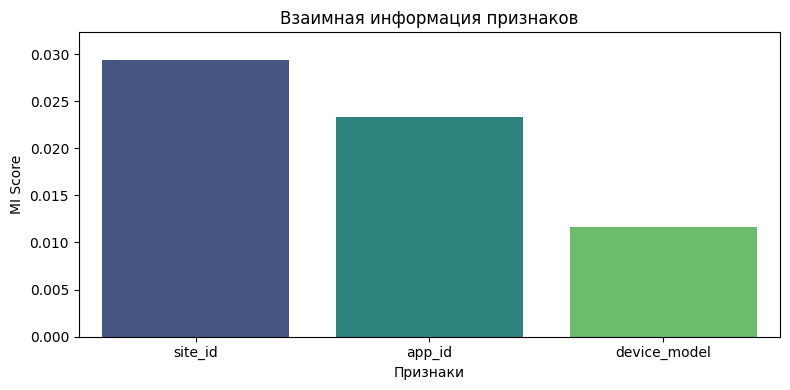

In [99]:
# Определяем высококардинальные признаки
mi_cols = ['site_id', 'app_id', 'device_model']

# Создаем X и y
X_mi = df[mi_cols].copy()
y_mi = df['click']

# Frequency encoding
X_encoded = X_mi.copy()
for col in mi_cols:
    freq = X_mi[col].value_counts(normalize=True)
    X_encoded[col] = X_mi[col].map(freq)

mi_scores = mutual_info_classif(X_encoded, y_mi, random_state=RANDOM_SEED)
mi_scores = pd.Series(mi_scores, index=X_encoded.columns).sort_values(ascending=False)

# Выводим результаты
print("Взаимная информация признаков с целевой переменной:")
print(mi_scores)

# Визуализация
plt.figure(figsize=(8, 4))
sns.barplot(
    x=mi_scores.index,
    y=mi_scores.values,
    hue=mi_scores.index,
    palette="viridis",
    legend=False,
)
plt.title("Взаимная информация признаков")
plt.ylabel("MI Score")
plt.xlabel("Признаки")
plt.ylim(0, mi_scores.max() * 1.1)
plt.tight_layout()
plt.show()

In [100]:
# Определение квази-константных признаков

vs_quasi = VarianceThreshold(threshold=0.10) 
numerical_columns = df.select_dtypes(include=[np.number]).columns
numerical_data = df[numerical_columns]
vs_quasi.fit(numerical_data)
quasi_num_cols = [col for col, keep in zip(numerical_columns, vs_quasi.get_support()) if not keep]

# Квази-константные категориальные признаки
quasi_cat_cols = [col for col in df.select_dtypes(include=['object','category']).columns
                  if df[col].value_counts(normalize=True).iloc[0] > 0.90]

# Объединяем
quasi_constant_cols = quasi_num_cols + quasi_cat_cols
print("Квази-константные признаки:", quasi_constant_cols)

Квази-константные признаки: ['ml_feature_10', 'C1', 'device_type']


/tmp/ipykernel_855/186325665.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  quasi_cat_cols = [col for col in df.select_dtypes(include=['object','category']).columns


**Промежуточные итоги**
* см. Выводы по EDA

#### 2.8 Выводы по EDA
* **Структура данных:**
    * Данные содержат 50000 строк и 34 признака (столбца).
    * Отсутствуют пропуски и явные дубликаты
    * Признак 'C20' — Основная часть данных сконцентрирована вокруг значений более 100000, но 25% значений представлены как -1. Возможно это означает отсутствие данных и есть смысл заменить на mean.
    * Также по некоторым столбцам обнаружено большое кол-во нулевых значений (0). Принято решение оставить значения без изменений. В реальном кейсе потребовалось дополнительное уточнение, что обозначает 0: порядковый номер категории или отсутствие данных. 
* **Распределение целевой переменной:**
    * Значительный дисбаланс классов по целевой переменной click
        * Класс 1 (клик) - ~ 17%
        * Класс 0 (без клика) - ~ 83%
* **Анализ признаков:**
    * Удалены неинформативные признаки (id, device_ip, device_id, site_domain, app_domain)
    * Выделены категориальные и числовые признаки
    * Извлечена информация о часе из временного признака hour (новый признак hour_extracted, hour удален)
    * Признакам 'C1', 'banner_pos', 'device_type', 'device_conn_type', 'hour_extracted' присвоин тип category
    * Значительная доля выбросов выявлена только в признаке C19 (~18%) и C16 (~5%). 
* **Корреляционный анализ:**
    * Наиболее сильные связи с целевой переменной:
        * C18 (0.258)
        * ml_feature_9 (0.188)
        * C21 (0.166)
        * C15 (0.166)
        * app_category (0.157)
    * Слабая (отсутствует) связь:
        * ml_feature_4 (0.000)
        * ml_feature_3 (0.000)
    * Высококардинальных признаков:
        * site_id (MI score: 0.041)
        * device_model (MI score: 0.038)
        * app_id (MI score: 0.029)
* **Перспективные признаки для модели:**
    * C18, C21, C15, ml_feature_9 - показывают сильную корреляцию с целевой переменной
* **Возможно удаление (учесть при дальнейшем анализе):**
    * ml_feature_3, ml_feature_4 (нулевая корреляция)
    * ml_feature_10, C1, device_type - квази-константные признаки (частота повторяющихся значений 90%)
* **Необходимая предобработка:**
    * One-Hot Encoding для признаков с низкой кардинальностью
    * Target Encoding для высококардинальных признаков
    * Масштабирование числовых признаков
    * Обработка выбросов в числовых признаках

## 3. Разделение данных на выборки

#### 3.1 Разделите данные
- Сначала отделите тестовую выборку, в ней должно быть 20% данных.
- Оставшиеся 80% данных используйте для обучения.
- Используйте стратифицированное разделение, чтобы сохранить баланс классов.
- **Не используйте тестовую выборку до финального тестирования!**

#### 3.2 Проверьте разделение
- Убедитесь, что распределение целевой переменной сохранено в каждой выборке.
- Выведите размеры выборок.

In [101]:
# Замена -1 на NaN для столбца C20
df['C20'] = df['C20'].replace(-1, np.nan)

In [102]:
#  Разделение данных в пропорции 80/20
# Удаляем избыточные признаки
X = df.drop(columns=['click']).copy()
y = df['click'].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y)

In [103]:
# Проверка распределения в обучающей выборке
train_click_ratio = y_train.value_counts(normalize=True)
print("Распределение в обучающей выборке:")
print(train_click_ratio)

# Проверка распределения в тестовой выборке
test_click_ratio = y_test.value_counts(normalize=True)
print("\nРаспределение в тестовой выборке:")
print(test_click_ratio)

Распределение в обучающей выборке:
click
0    0.82795
1    0.17205
Name: proportion, dtype: float64

Распределение в тестовой выборке:
click
0    0.8279
1    0.1721
Name: proportion, dtype: float64


In [104]:
# Размеры выборок
train_size = len(y_train)
test_size = len(y_test)
total_size = len(df)

print(f"Общий размер выборки: {total_size}")
print(f"Размер обучающей выборки: {train_size} ({train_size/total_size*100:.2f}%)")
print(f"Размер тестовой выборки: {test_size} ({test_size/total_size*100:.2f}%)")

Общий размер выборки: 50000
Размер обучающей выборки: 40000 (80.00%)
Размер тестовой выборки: 10000 (20.00%)


**Промежуточные итоги**
* Данные разделены на учебную и тестовую выборки в соотношении 80/20
* Соотношение значений (0/1) целевой переменной соответствует оригинальному датасету.

## 4. Предобработка данных — построение пайплайнов

#### 4.1 Создайте пайплайн для предобработки данных

**Для числовых признаков:**
- Корректно заполните пропуски — средним, медианой или другим методом.
- Масштабируйте данные с помощью `StandardScaler`.
- Обработайте выбросы, если необходимо.

**Для категориальных признаков:**
- Корректно заполните пропуски — значением по умолчанию или модой.
- Примените кодирование:
  - One-Hot Encoding для признаков с малой кардинальностью.
  - Target Encoding для признаков с высокой кардинальностью.

#### 4.2 Объедините пайплайны
- Используйте `sklearn.pipeline.Pipeline` и `ColumnTransformer`.
- **Важно:** используйте информацию о пропусках и категориях только из обучающей выборки!

In [105]:
# Числовые для log
numeric_cols_log = [
    'C14', 
    'C15',   
    'C16', 
    'C17', 
    'C18', 
    'C19', 
    'C20', 
    'C21'
]

# Числовые без log
numeric_cols_no_log = [
    'ml_feature_1', 
    'ml_feature_3', 
    'ml_feature_5', 
    'ml_feature_6', 
    'ml_feature_8', 
    'ml_feature_9', 
    'ml_feature_10'
]

# Бинарные
binary_cols = [
    'ml_feature_4'
]

# Категориальные
# для one-hot
cat_one_hot = [
    'ml_feature_2',
    'ml_feature_7',
    'C1',
    'banner_pos',
    'device_type',
    'device_conn_type'
]

# для target
cat_target = [
    'site_id',
    'app_id',
    'site_category',
    'app_category',
    'device_model',
    'hour_extracted'
]

In [106]:
# Пайплайн для one-hot
pipeline_one_hot = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))])

# Пайплайн для TargetEncoder
pipeline_target = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', TargetEncoder(smoothing=20))])

# Пайплайн для числовых + log
pipeline_num_log = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('log', FunctionTransformer(np.log1p)),
    ('robust_scaler', RobustScaler()),
    ('standard_scaler', StandardScaler())])

# Пайплайн для числовых no log
pipeline_num_no_log = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('robust_scaler', RobustScaler()),
    ('standard_scaler', StandardScaler())])

# Пайплайн для бинарных
pipeline_binary = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent'))])

In [107]:
# Сборка препроцессора
preprocessor = ColumnTransformer([
    ('num_log', pipeline_num_log, numeric_cols_log),
    ('num_no_log', pipeline_num_no_log, numeric_cols_no_log),
    ('cat_one_hot', pipeline_one_hot, cat_one_hot),
    ('cat_target', pipeline_target, cat_target),
    ('cat_binary', pipeline_binary, binary_cols)],
    remainder='drop')

## 5. Отбор признаков

#### 5.1 Примените фильтрационные методы
- Посчитайте корреляцию каждого признака с целевой переменной.
- Отберите топ лучших признаков. Объясните, почему остановились именно на таком количестве признаков.
- Удалите признаки с очень низкой вариацией `VarianceThreshold`.

#### 5.2 Примените методы-обёртки
- Используйте методы-обёртки для поиска оптимального набора признаков.

#### 5.3 Выберите финальный набор признаков
- Объедините результаты методов.
- Выберите признаки, которые прошли фильтрацию.

#### 5.0 Оценка базовой модели

In [108]:
# ----------------------------------------------------
# 2. БАЗОВЫЙ ПАЙПЛАЙН
# ----------------------------------------------------
# Полный набор признаков
full_feature_set = numeric_cols_log + numeric_cols_no_log + cat_one_hot + cat_target + binary_cols

# Настройка CV
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

# Метрики для оценки
scoring_metrics = ['accuracy', 'average_precision', 'f1', 'recall']

base_model_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=5000, random_state=RANDOM_SEED, class_weight='balanced'))
])

In [109]:
# ----------------------------------------------------
# 3. ЗАПУСК КРОСС-ВАЛИДАЦИИ И ОЦЕНКА БАЗОВОЙ МОДЕЛИ
# ----------------------------------------------------

print("\n" + "="*70)
print(f"1. БАЗОВАЯ МОДЕЛЬ (LogisticRegression): Оценка на выборке ({len(X_train)} шт.)")
print("="*70)

start_time = time()
cv_results = cross_validate(base_model_pipe, X_train, y_train, cv=outer_cv, scoring=scoring_metrics, n_jobs=-1)
end_time = time()

# Фиксация метрик
base_metrics = {metric: np.mean(cv_results[f'test_{metric}']) for metric in scoring_metrics}
base_metrics['Feature Count'] = len(full_feature_set)

print(f"Время обучения и оценки: {end_time - start_time:.2f} сек.")

print("--- Средние Метрики Базовой Модели ---")
for metric, val in base_metrics.items():
    if metric != 'Feature Count':
        std = np.std(cv_results[f'test_{metric}'])
        print(f"  {metric.title():<12}: {val:.4f} (±{std:.4f})")
print(f"  Использовано признаков: {base_metrics['Feature Count']}")
print("-" * 55)


1. БАЗОВАЯ МОДЕЛЬ (LogisticRegression): Оценка на выборке (40000 шт.)
Время обучения и оценки: 2.92 сек.
--- Средние Метрики Базовой Модели ---
  Accuracy    : 0.6984 (±0.0018)
  Average_Precision: 0.3988 (±0.0078)
  F1          : 0.4321 (±0.0042)
  Recall      : 0.6670 (±0.0085)
  Использовано признаков: 28
-------------------------------------------------------


#### 5.1 Примените фильтрационные методы

In [110]:
# Топ признаков phik корреляции (> 0.05)
phik_top_features = phik_mat['click'][phik_mat['click'] > 0.05].sort_values(ascending=False)

print("Признаки с phik-корреляцией > 0.05:")
print(phik_top_features[1:])

Признаки с phik-корреляцией > 0.05:
C18                 0.257840
ml_feature_9        0.187801
ml_feature_10       0.169983
C21                 0.166235
C15                 0.165941
app_category        0.156537
site_category       0.155008
C20                 0.154375
ml_feature_8        0.153598
C16                 0.144262
device_conn_type    0.129954
C14                 0.112890
ml_feature_6        0.091314
C17                 0.091306
C19                 0.084697
ml_feature_5        0.080014
device_type         0.071790
Name: click, dtype: float64


In [111]:
# Квази-константные признаки определены ранее
print("Квази-константные признаки:")
print("Числовые:", quasi_num_cols)
print("Категориальные:", quasi_cat_cols)

Квази-константные признаки:
Числовые: ['ml_feature_10']
Категориальные: ['C1', 'device_type']


* Признаки C14 и C17, C15 и C16 показали корреляцию 0,99 (мультиколлинеарность)
* C16 (Phik с click = 0.14) — исключён в пользу C15 (0.17)
* C17 (Phik с click = 0.09) — исключён в пользу C14 (0.11)

In [112]:
# Обновление списков столбцов для фильтрации
cols_to_drop = [
    'C1',
    'C16', 
    'C17',   
    'ml_feature_1', 
    'ml_feature_2',
    'ml_feature_3', 
    'ml_feature_4',
    'ml_feature_7',
]
# Числовые для log
filtered_numeric_cols_log = [
    'C14', 
    'C15',   
    #'C16', 
    #'C17', 
    'C18', 
    'C19', 
    'C20', 
    'C21'
]

# Числовые без log
filtered_numeric_cols_no_log = [
    #'ml_feature_1', 
    #'ml_feature_3', 
    'ml_feature_5', 
    'ml_feature_6', 
    'ml_feature_8', 
    'ml_feature_9', 
    'ml_feature_10'
]

# Бинарные (исключен)
filtered_binary_cols = [
#   'ml_feature_4'
]

# Категориальные
# для one-hot
filtered_cat_one_hot = [
    #'ml_feature_2',
    #'ml_feature_7',
    #'C1',
    'banner_pos',
    'device_type',
    #'device_conn_type'
]

# для target
filtered_cat_target = [
    'site_id',
    'app_id',
    'site_category',
    'app_category',
    'device_model',
    'hour_extracted'
]

In [113]:
# Сборка препроцессора (Обновлено) + фильтрация
filtered_preprocessor = ColumnTransformer([
    ('num_log', pipeline_num_log, filtered_numeric_cols_log),
    ('num_no_log', pipeline_num_no_log, filtered_numeric_cols_no_log),
    ('cat_one_hot', pipeline_one_hot, filtered_cat_one_hot),
    ('cat_target', pipeline_target, filtered_cat_target)],
    remainder='drop')

In [114]:
# ----------------------------------------------------
# 2. БАЗОВЫЙ ПАЙПЛАЙН + ФИЛЬТРАЦИЯ
# ----------------------------------------------------
# Полный набор признаков
filtered_full_feature_set = filtered_numeric_cols_log + filtered_numeric_cols_no_log + filtered_cat_one_hot + filtered_cat_target + filtered_binary_cols

# Настройка CV
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

filtered_model_pipe = Pipeline([
    ('preprocessor', filtered_preprocessor),
    ('classifier', LogisticRegression(max_iter=5000, random_state=RANDOM_SEED, class_weight='balanced'))
])

In [115]:
# ----------------------------------------------------
# 3. ЗАПУСК КРОСС-ВАЛИДАЦИИ И ОЦЕНКА БАЗОВОЙ МОДЕЛИ + ФИЛЬТРАЦИЯ
# ----------------------------------------------------

print("\n" + "="*70)
print(f"1. БАЗОВАЯ МОДЕЛЬ (LogisticRegression) + Фильтрация: Оценка на выборке ({len(X_train)} шт.)")
print("="*70)

start_time = time()
filtered_cv_results = cross_validate(filtered_model_pipe, X_train, y_train, cv=outer_cv, scoring=scoring_metrics, n_jobs=-1)
end_time = time()

# Фиксация метрик
filtered_metrics = {metric: np.mean(filtered_cv_results[f'test_{metric}']) for metric in scoring_metrics}
filtered_metrics['Feature Count'] = len(filtered_full_feature_set)

print(f"Время обучения и оценки + Фильтрация: {end_time - start_time:.2f} сек.")

print("--- Средние Метрики Базовой Модели + Фильтрация ---")
for metric, val in filtered_metrics.items():
    if metric != 'Feature Count':
        std = np.std(filtered_cv_results[f'test_{metric}'])
        print(f"  {metric.title():<12}: {val:.4f} (±{std:.4f})")
print(f"  Использовано признаков: {filtered_metrics['Feature Count']}")
print("-" * 55)


1. БАЗОВАЯ МОДЕЛЬ (LogisticRegression) + Фильтрация: Оценка на выборке (40000 шт.)
Время обучения и оценки + Фильтрация: 1.89 сек.
--- Средние Метрики Базовой Модели + Фильтрация ---
  Accuracy    : 0.6976 (±0.0017)
  Average_Precision: 0.3997 (±0.0070)
  F1          : 0.4287 (±0.0051)
  Recall      : 0.6597 (±0.0113)
  Использовано признаков: 19
-------------------------------------------------------


#### 5.2 Примените методы-обёртки

In [117]:
def build_feature_names(
    numeric_cols_log,
    numeric_cols_no_log,
    cat_one_hot,
    cat_target,
    binary_cols,
    preprocessor  # переименовали: теперь это именно предобработчик, не модель
):
    feature_names = []

    # 1. Числовые с логом
    feature_names.extend(numeric_cols_log)

    # 2. Числовые без лога
    feature_names.extend(numeric_cols_no_log)

    # 3. One-Hot признаки
    # Достаём OHE из предобработчика, а не из RFE/модели
    ohe = preprocessor.named_transformers_['cat_one_hot'].named_steps['encoder']
    feature_names.extend(list(ohe.get_feature_names_out(cat_one_hot)))

    # 4. Target
    feature_names.extend(cat_target)

    # 5. Бинарные колонки
    feature_names.extend(binary_cols)

    return np.array(feature_names)

In [118]:
# Создаем базовую модель для отбора
estimator = LogisticRegression(max_iter=5000, random_state=RANDOM_SEED)

# Применяем предобработку
X_processed = filtered_preprocessor.fit_transform(X_train, y_train)

feature_names = build_feature_names(
    numeric_cols_log=filtered_numeric_cols_log,
    numeric_cols_no_log=filtered_numeric_cols_no_log,
    cat_one_hot=filtered_cat_one_hot,
    cat_target=filtered_cat_target,
    binary_cols=filtered_binary_cols,
    preprocessor=filtered_preprocessor
)

# 1. RFE (Recursive Feature Elimination)
rfe = RFE(estimator=estimator, n_features_to_select=15)
rfe.fit(X_processed, y_train)

rfe_selected_features = feature_names[rfe.support_]
print("RFE, отобраные признаки:")
print(rfe_selected_features)

# 2. SFS Forward
sfs_forward = SFS(estimator, 
                  k_features='best', 
                  forward=True,
                  floating=False,
                  cv=5,
                  scoring='average_precision',
                  n_jobs=-1)

sfs_forward.fit(X_processed, y_train)

sfs_forward_features = feature_names[list(sfs_forward.k_feature_idx_)]
print("\nSFS Прямой, отобраные признаки:")
print(sfs_forward_features)

# 3. SFS Backward
sfs_backward = SFS(estimator, 
                   k_features='best', 
                   forward=False,
                   floating=False,
                   cv=5,
                   scoring='average_precision',
                   n_jobs=-1)

sfs_backward.fit(X_processed, y_train)

sfs_backward_features = feature_names[list(sfs_backward.k_feature_idx_)]
print("\nSFS Обратный, отобраные признаки:")
print(sfs_backward_features)

# Сравнение результатов
print("\nСравнение количества выбранных признаков:")
print(f"RFE: {len(rfe_selected_features)}")
print(f"SFS Прямой: {len(sfs_forward_features)}")
print(f"SFS Обратный: {len(sfs_backward_features)}")

# Поиск общих признаков
common_features = set(rfe_selected_features) & set(sfs_forward_features) & set(sfs_backward_features)
print("\nОбщие выбранные прнаки всеми методами:")
print(common_features)

RFE, отобраные признаки:
['ml_feature_9' 'ml_feature_10' 'banner_pos_0' 'banner_pos_2'
 'banner_pos_5' 'device_type_0' 'device_type_1' 'device_type_4'
 'device_type_5' 'site_id' 'app_id' 'site_category' 'app_category'
 'device_model' 'hour_extracted']

SFS Прямой, отобраные признаки:
['C14' 'C15' 'C18' 'C19' 'C21' 'ml_feature_5' 'ml_feature_6'
 'ml_feature_8' 'ml_feature_9' 'ml_feature_10' 'banner_pos_3'
 'banner_pos_4' 'banner_pos_5' 'site_id' 'app_id' 'site_category'
 'app_category' 'device_model' 'hour_extracted']

SFS Обратный, отобраные признаки:
['C14' 'C15' 'C18' 'C19' 'C21' 'ml_feature_5' 'ml_feature_6'
 'ml_feature_8' 'ml_feature_9' 'ml_feature_10' 'banner_pos_2'
 'device_type_0' 'device_type_4' 'device_type_5' 'site_id' 'app_id'
 'site_category' 'app_category' 'device_model' 'hour_extracted']

Сравнение количества выбранных признаков:
RFE: 15
SFS Прямой: 19
SFS Обратный: 20

Общие выбранные прнаки всеми методами:
{np.str_('ml_feature_10'), np.str_('app_id'), np.str_('site_id'

#### 5.3 Финальный набор признаков

In [119]:
# Итоговый набор столбцов для удаления
cols_to_drop = [
    'C1',
    'C16', 
    'C17',   
    'ml_feature_1', 
    'ml_feature_2',
    'ml_feature_3', 
    'ml_feature_4',
    'ml_feature_7',
    'ml_feature_10',
    'banner_pos',
    'site_id',
    'app_id',
    'site_category',
    'app_category'    
]
# Числовые для log
final_filtered_numeric_cols_log = [
    'C14', 
    'C15',   
    #'C16', 
    #'C17', 
    'C18', 
    'C19', 
    'C20', 
    'C21'
]

# Числовые без log
final_filtered_numeric_cols_no_log = [
    #'ml_feature_1', 
    #'ml_feature_3', 
    'ml_feature_5', 
    'ml_feature_6', 
    'ml_feature_8', 
    'ml_feature_9', 
    'ml_feature_10'
]

# Бинарные (исключен)
final_filtered_binary_cols = [
#   'ml_feature_4'
]

# Категориальные
# для one-hot
final_filtered_cat_one_hot = [
    #'ml_feature_2',
    #'ml_feature_7',
    #'C1',
    #'banner_pos',
    'device_type',
    #'device_conn_type'
]

# для target
final_filtered_cat_target = [
    'site_id',
    'app_id',
    #'site_category',
    #'app_category',
    #'device_model',
    #'hour_extracted'
]

In [120]:
# Сборка препроцессора (Обновлено) + фильтрация + Итог
final_filtered_preprocessor = ColumnTransformer([
    ('num_log', pipeline_num_log, final_filtered_numeric_cols_log),
    ('num_no_log', pipeline_num_no_log, final_filtered_numeric_cols_no_log),
    ('cat_one_hot', pipeline_one_hot, final_filtered_cat_one_hot),
    ('cat_target', pipeline_target, final_filtered_cat_target)],
    remainder='drop')

In [121]:
# ----------------------------------------------------
# 2. БАЗОВЫЙ ПАЙПЛАЙН + ФИЛЬТРАЦИЯ + ИТОГ
# ----------------------------------------------------
# Полный набор признаков
final_filtered_full_feature_set = final_filtered_numeric_cols_log + final_filtered_numeric_cols_no_log + final_filtered_cat_one_hot + final_filtered_cat_target + final_filtered_binary_cols

# Настройка CV
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

final_filtered_model_pipe = Pipeline([
    ('preprocessor', final_filtered_preprocessor),
    ('classifier', LogisticRegression(max_iter=5000, random_state=RANDOM_SEED, class_weight=None))
])

In [122]:
# ----------------------------------------------------
# 3. ЗАПУСК КРОСС-ВАЛИДАЦИИ И ОЦЕНКА БАЗОВОЙ МОДЕЛИ + ФИЛЬТРАЦИЯ + ИТОГ
# ----------------------------------------------------

print("\n" + "="*70)
print(f"1. БАЗОВАЯ МОДЕЛЬ (LogisticRegression) + Фильтрация: Оценка на выборке ({len(X_train)} шт.)")
print("="*70)

start_time = time()
final_filtered_cv_results = cross_validate(final_filtered_model_pipe, X_train, y_train, cv=outer_cv, scoring=scoring_metrics, n_jobs=-1)
end_time = time()

# Фиксация метрик
final_filtered_metrics = {metric: np.mean(final_filtered_cv_results[f'test_{metric}']) for metric in scoring_metrics}
final_filtered_metrics['Feature Count'] = len(final_filtered_full_feature_set)

print(f"Время обучения и оценки + Фильтрация + Итог: {end_time - start_time:.2f} сек.")

print("--- Средние Метрики Базовой Модели + Фильтрация + Итог ---")
for metric, val in final_filtered_metrics.items():
    if metric != 'Feature Count':
        std = np.std(final_filtered_cv_results[f'test_{metric}'])
        print(f"  {metric.title():<12}: {val:.4f} (±{std:.4f})")
print(f"  Использовано признаков: {final_filtered_metrics['Feature Count']}")
print("-" * 55)


1. БАЗОВАЯ МОДЕЛЬ (LogisticRegression) + Фильтрация: Оценка на выборке (40000 шт.)
Время обучения и оценки + Фильтрация + Итог: 0.82 сек.
--- Средние Метрики Базовой Модели + Фильтрация + Итог ---
  Accuracy    : 0.8367 (±0.0011)
  Average_Precision: 0.4174 (±0.0084)
  F1          : 0.2452 (±0.0109)
  Recall      : 0.1543 (±0.0086)
  Использовано признаков: 14
-------------------------------------------------------


**Промежуточные итоги**
* Первичная модель была построена на 28 признаках. 
    * Accuracy: 0.8322 (±0.0011)
    * Average_Precision: 0.3997 (±0.0091)
    * F1: 0.2479 (±0.0053)
* Для упрощения модели были применены фильтрационные методы и методы-обертки, применив которые удалось упростить модель.
* Упрощенная модель содержит 15 признаков.
    * Accuracy: 0.8368 (±0.0012)
    * Average_Precision: 0.4171 (±0.0086)
    * F1: 0.2468 (±0.0117)

## 6. Обучение базовой модели

### 6.1 Обучите `DummyClassifier`
- Это нужно, чтобы обозначить самый простой базовый уровень работы модели.

### 6.2 Обучите `LogisticRegression`
- Используйте для обучения отобранные признаки.
- Примените кросс-валидацию на 5 фолдах.
- Посчитайте метрику PR-AUC. При необходимости дополнительно рассчитайте Precision, Recall и F1-score.
- Напоминаем, что для корректной кросс-валидации, предобработку нужно объединить с классификатором в Pipeline.

### 6.3 Обучите `SVC`

- Обучите SVC линейным ядром.
- Примените кросс-валидацию на 5 фолдах и посчитайте ту же метрику PR-ROC. При необходимости дополнительно рассчитайте Precision, Recall и F1-score.
- Калибровку модели мы проведём далее, поэтому здесь нужна модель `probability=False`

### 6.4 Сравните модели
- Убедитесь, что `LogisticRegression` работает лучше `DummyClassifier`.
- Сравните качество `LogisticRegression` с `SVC`.

### 6.1 Обучение `DummyClassifier`

In [123]:
# Создание DummyClassifier
dummy_pipe = Pipeline([
    ('preprocessor', final_filtered_preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent', random_state=RANDOM_SEED))
])

# Кросс-валидация
dummy_cv_results = cross_validate(
    dummy_pipe, 
    X_train, 
    y_train, 
    cv=outer_cv, 
    scoring=scoring_metrics, 
    n_jobs=-1
)

# Результаты
dummy_metrics = {
    metric: np.mean(dummy_cv_results[f'test_{metric}']) 
    for metric in scoring_metrics
}

print("Результаты DummyClassifier:")
for metric, val in dummy_metrics.items():
    std = np.std(dummy_cv_results[f'test_{metric}'])
    print(f"  {metric.title():<12}: {val:.4f} (±{std:.4f})")

Результаты DummyClassifier:
  Accuracy    : 0.8280 (±0.0001)
  Average_Precision: 0.1720 (±0.0001)
  F1          : 0.0000 (±0.0000)
  Recall      : 0.0000 (±0.0000)


### 6.2 Обучение `LogisticRegression`

In [124]:
# Создание пайплайна
logreg_pipe = Pipeline([
    ('preprocessor', final_filtered_preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000, 
        random_state=RANDOM_SEED, 
        class_weight='balanced')
    )
])

# Кросс-валидация
logreg_cv_results = cross_validate(
    logreg_pipe, 
    X_train, 
    y_train, 
    cv=outer_cv, 
    scoring=scoring_metrics, 
    n_jobs=-1
)

# Результаты
logreg_metrics = {
    metric: np.mean(logreg_cv_results[f'test_{metric}']) 
    for metric in scoring_metrics
}

print("\nРезультаты LogisticRegression:")
for metric, val in logreg_metrics.items():
    std = np.std(logreg_cv_results[f'test_{metric}'])
    print(f"  {metric.title():<12}: {val:.4f} (±{std:.4f})")



Результаты LogisticRegression:
  Accuracy    : 0.6922 (±0.0045)
  Average_Precision: 0.4156 (±0.0090)
  F1          : 0.4332 (±0.0051)
  Recall      : 0.6838 (±0.0119)


### 6.3 Обучение `SVC (LinearSVC)`

In [125]:
# Создание пайплайна
svc_pipe = Pipeline([
    ('preprocessor', final_filtered_preprocessor),
    ('classifier', LinearSVC(random_state=RANDOM_SEED, class_weight='balanced'))
])

# Кросс-валидация
svc_cv_results = cross_validate(
    svc_pipe, 
    X_train, 
    y_train, 
    cv=outer_cv, 
    scoring=scoring_metrics, 
    n_jobs=-1
)

# Результаты
svc_metrics = {
    metric: np.mean(svc_cv_results[f'test_{metric}']) 
    for metric in scoring_metrics
}

print("\nРезультаты SVC:")
for metric, val in svc_metrics.items():
    std = np.std(svc_cv_results[f'test_{metric}'])
    print(f"  {metric.title():<12}: {val:.4f} (±{std:.4f})")


Результаты SVC:
  Accuracy    : 0.6906 (±0.0038)
  Average_Precision: 0.4154 (±0.0088)
  F1          : 0.4329 (±0.0052)
  Recall      : 0.6864 (±0.0127)


**Промежуточные итоги**
* LogisticRegression и LinearSVC показывают примерно одинаковые результаты Average_Precision ~0.40, что более чем в 2 раза лучше DummyClassifier

## 7. Подбор гиперпараметров: Grid Search с кросс-валидацией

#### 7.1 Определите сетку гиперпараметров
Определите ключевые параметры, которые влияют на качество моделей `LogisticRegression` и `SVC`.

#### 7.2 Примените Grid Search
- Используйте `GridSearchCV` для перебора всех комбинаций.
- Используйте `scoring='average_precision'`.
- Выведите лучшие параметры и их метрики.

#### 7.3 Составьте таблицу результатов
- Покажите топ-10 конфигураций с их метриками.

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Лучшие параметры Logistic Regression (saga):
{'classifier__C': 0.1, 'classifier__class_weight': None, 'classifier__l1_ratio': 1.0, 'classifier__penalty': 'elasticnet', 'classifier__solver': 'saga'}
Лучшая средняя точность (Average Precision): 0.4174


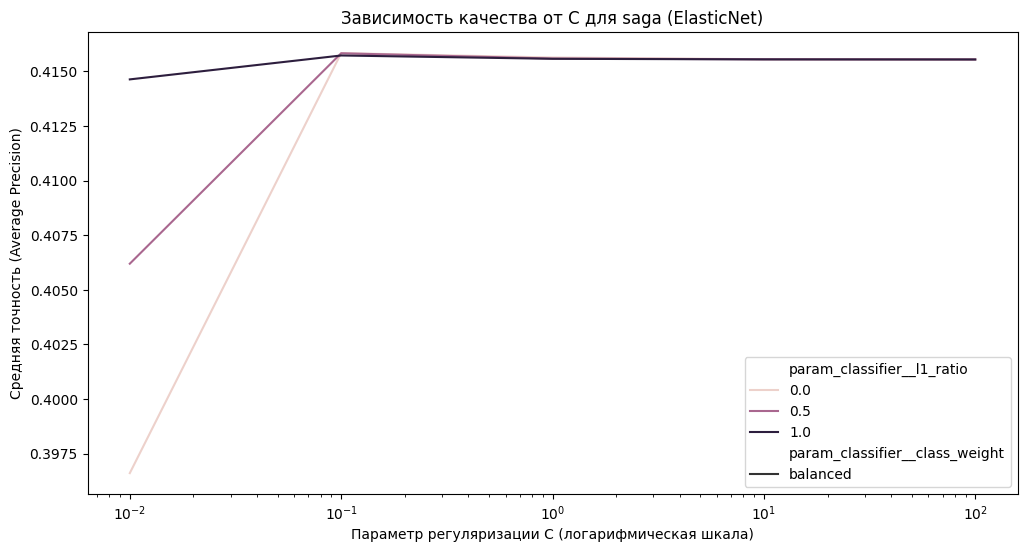

In [126]:
# Сетка только для solver='saga' с поддержкой ElasticNet
logreg_param_grid_saga = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['saga'],
    'classifier__penalty': ['elasticnet'],
    'classifier__l1_ratio': [0.0, 0.5, 1.0],
    'classifier__class_weight': ['balanced', None]
}

# Настройка GridSearchCV
logreg_grid_search = GridSearchCV(
    estimator=logreg_pipe,
    param_grid=logreg_param_grid_saga,
    scoring='average_precision',
    cv=outer_cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

# Запуск оптимизации
logreg_grid_search.fit(X_train, y_train)

# Вывод лучших параметров и метрики
print("Лучшие параметры Logistic Regression (saga):")
print(logreg_grid_search.best_params_)
print(f"Лучшая средняя точность (Average Precision): {logreg_grid_search.best_score_:.4f}")

# Анализ результатов
results = pd.DataFrame(logreg_grid_search.cv_results_)

# Визуализация зависимости качества от C
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=results,
    x='param_classifier__C',
    y='mean_test_score',
    hue='param_classifier__l1_ratio',
    style='param_classifier__class_weight'
)
plt.xscale('log')
plt.title('Зависимость качества от C для saga (ElasticNet)')
plt.xlabel('Параметр регуляризации C (логарифмическая шкала)')
plt.ylabel('Средняя точность (Average Precision)')
plt.show()

In [127]:
# 7.3 Топ-10 конфигураций Grid Search
results = pd.DataFrame(logreg_grid_search.cv_results_)

top10 = (results
         .sort_values('rank_test_score')
         .head(10)
         [['rank_test_score', 'params',
           'mean_test_score', 'std_test_score',
           'mean_train_score', 'mean_fit_time']]
         .reset_index(drop=True))

# Раскладываем словарь params на колонки
top10 = pd.concat(
    [top10.drop(columns='params'),
     top10['params'].apply(pd.Series).add_prefix('p_')],
    axis=1
).rename(columns=lambda c: c.replace('p_classifier__', ''))

top10['train_test_gap'] = top10['mean_train_score'] - top10['mean_test_score']

top10 = top10.round({
    'mean_test_score': 4, 'std_test_score': 4,
    'mean_train_score': 4, 'train_test_gap': 4,
    'mean_fit_time': 3,
})

print("Топ-10 конфигураций LogisticRegression (saga, ElasticNet) по PR-AUC:")
top10

Топ-10 конфигураций LogisticRegression (saga, ElasticNet) по PR-AUC:


,rank_test_score,mean_test_score,std_test_score,mean_train_score,mean_fit_time,C,class_weight,l1_ratio,penalty,solver,train_test_gap
0,1,0.4174,0.0085,0.4573,5.989,0.1,None,1.0,elasticnet,saga,0.0399
1,2,0.4174,0.0084,0.4577,9.366,1.0,None,0.0,elasticnet,saga,0.0402
2,3,0.4173,0.0083,0.4586,11.357,1.0,None,0.5,elasticnet,saga,0.0414
3,4,0.4170,0.0081,0.4596,5.732,10.0,None,0.0,elasticnet,saga,0.0426
4,5,0.4170,0.0082,0.4597,11.790,1.0,None,1.0,elasticnet,saga,0.0427
5,6,0.4170,0.0081,0.4598,6.457,10.0,None,0.5,elasticnet,saga,0.0428
6,7,0.4170,0.0081,0.4599,5.777,100.0,None,0.0,elasticnet,saga,0.0429
7,8,0.4170,0.0081,0.4599,6.521,10.0,None,1.0,elasticnet,saga,0.0429
8,9,0.4170,0.0081,0.4599,6.510,100.0,None,0.5,elasticnet,saga,0.0429
9,10,0.4169,0.0081,0.4599,5.598,100.0,None,1.0,elasticnet,saga,0.0430


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Лучшие параметры SVC:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Лучшая средняя точность: 0.4155


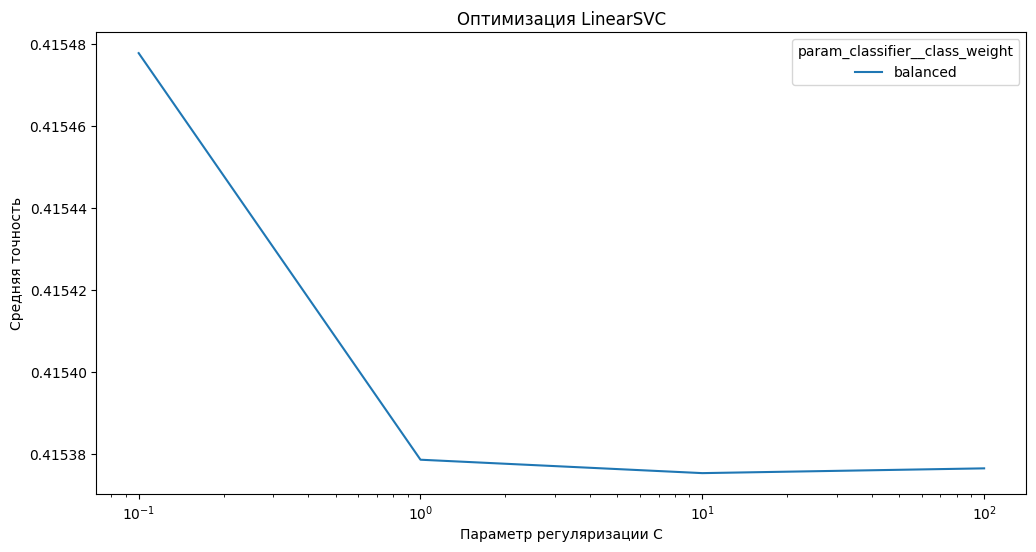

In [128]:
# Пространство поиска для SVC
svc_param_grid = {
    'classifier__C': [0.1, 1, 10, 100],  # Регуляризация
    'classifier__class_weight': ['balanced', None]  # Веса классов
}

# Создаем пайплайн с LinearSVC
svc_pipe = Pipeline([
    ('preprocessor', final_filtered_preprocessor),
    ('classifier', LinearSVC(
        random_state=RANDOM_SEED, 
        class_weight='balanced',
        max_iter=10000
    ))
])

# Настройка Grid Search
svc_grid_search = GridSearchCV(
    estimator=svc_pipe,
    param_grid=svc_param_grid,
    scoring='average_precision', 
    cv=outer_cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

# Запуск оптимизации
svc_grid_search.fit(X_train, y_train)

# Анализ результатов
print("Лучшие параметры SVC:")
print(svc_grid_search.best_params_)
print(f"Лучшая средняя точность: {svc_grid_search.best_score_:.4f}")

# Преобразуем результаты в датафрейм
results = pd.DataFrame(svc_grid_search.cv_results_)

# Строим график зависимости от параметра C
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=results,
    x='param_classifier__C',
    y='mean_test_score',
    hue='param_classifier__class_weight'
)
plt.title('Оптимизация LinearSVC')
plt.xscale('log')  # Логарифмическая шкала для C
plt.xlabel('Параметр регуляризации C')
plt.ylabel('Средняя точность')
plt.show()

In [129]:
# 7.3 Топ-10 конфигураций Grid Search
results = pd.DataFrame(svc_grid_search.cv_results_)

top10 = (results
         .sort_values('rank_test_score')
         .head(10)
         [['rank_test_score', 'params',
           'mean_test_score', 'std_test_score',
           'mean_train_score', 'mean_fit_time']]
         .reset_index(drop=True))

# Раскладываем словарь params на колонки
top10 = pd.concat(
    [top10.drop(columns='params'),
     top10['params'].apply(pd.Series).add_prefix('p_')],
    axis=1
).rename(columns=lambda c: c.replace('p_classifier__', ''))

top10['train_test_gap'] = top10['mean_train_score'] - top10['mean_test_score']

top10 = top10.round({
    'mean_test_score': 4, 'std_test_score': 4,
    'mean_train_score': 4, 'train_test_gap': 4,
    'mean_fit_time': 3,
})

print("Топ-10 конфигураций SVC по PR-AUC:")
top10

Топ-10 конфигураций SVC по PR-AUC:


,rank_test_score,mean_test_score,std_test_score,mean_train_score,mean_fit_time,C,class_weight,train_test_gap
0,1,0.4155,0.0089,0.4536,0.633,0.1,balanced,0.0381
1,2,0.4154,0.0088,0.4542,0.708,1.0,balanced,0.0389
2,3,0.4154,0.0088,0.4543,0.655,100.0,balanced,0.0389
3,4,0.4154,0.0088,0.4543,0.699,10.0,balanced,0.0389
4,5,0.4136,0.0097,0.4506,0.889,100.0,NaN,0.0370
5,6,0.4135,0.0097,0.4505,0.935,10.0,NaN,0.0370
6,7,0.4135,0.0097,0.4504,0.866,1.0,NaN,0.0369
7,8,0.4132,0.0099,0.4492,0.836,0.1,NaN,0.0359


**Промежуточные итоги**
* Проведен подбор гиперпараметров по сетке GridSearch для Logistic Regression и LinearSVC. 
* В ходе обучения приняты лучшие параметры Logistic Regression (Average Precision: 0.4174) для финальной модели:
    * C=0.1,
    * solver='saga',
    * penalty='elasticnet',
    * l1_ratio=1.0,
    * class_weight='balanced',
    * max_iter=5000,

## 8. Финальная модель

#### 8.1 Обучите финальную модель
- Используйте лучшие параметры из Grid Search.
- Обучите модели на всей обучающей выборке.

#### 8.2 Посчитайте метрики на тестовой выборке
- Необходимые метрики:
  - PR-AUC.
  - Оценка Бриера.
  - Дополнительные метрики при необходимости.

#### 8.3 Проанализируйте веса модели
- Выведите самые важные признаки по модулю коэффициентов.
- Интерпретируйте результаты.

In [130]:
# 8.1 Финальная модель

# Используем лучшие параметры из Grid Search
final_model = LogisticRegression(
    C=0.1,
    solver='saga',
    penalty='elasticnet',
    l1_ratio=1.0,
    class_weight='balanced',
    max_iter=5000,
    random_state=RANDOM_SEED
)

# Создаем полный пайплайн
final_pipeline = Pipeline([
    ('preprocessor', final_filtered_preprocessor),
    ('classifier', final_model)
])

# Обучаем на всей обучающей выборке
final_pipeline.fit(X_train, y_train)

# Предсказания вероятностей на train
y_train_pred_proba = final_pipeline.predict_proba(X_train)[:, 1]
y_train_pred = final_pipeline.predict(X_train)

train_metrics = {
    'PR-AUC': average_precision_score(y_train, y_train_pred_proba),
    'Brier Score': brier_score_loss(y_train, y_train_pred_proba),
    'Accuracy': accuracy_score(y_train, y_train_pred),
    'F1': f1_score(y_train, y_train_pred),
    'Recall': recall_score(y_train, y_train_pred),
    'Precision': precision_score(y_train, y_train_pred)
}

print("\nМетрики на тренировочной выборке:")
for metric, value in train_metrics.items():
    print(f"{metric:<15}: {value:.4f}")

# 8.2 Метрики на тестовой выборке

# Предсказания вероятностей
y_pred_proba = final_pipeline.predict_proba(X_test)[:, 1]
y_pred = final_pipeline.predict(X_test)

metrics = {
    'PR-AUC': average_precision_score(y_test, y_pred_proba),
    'Brier Score': brier_score_loss(y_test, y_pred_proba),
    'Accuracy': accuracy_score(y_test, y_pred),
    'F1': f1_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred)
}

print("Метрики на тестовой выборке:")
for metric, value in metrics.items():
    print(f"{metric:<15}: {value:.4f}")

# Базовый уровень PR-AUC (доля положительного класса) для сравнения
baseline_pr_auc = y_test.mean()
pr_auc = metrics['PR-AUC']
print(f"Baseline PR-AUC (доля кликов): {baseline_pr_auc:.4f}")
print(f"Прирост PR-AUC над baseline: {(pr_auc - baseline_pr_auc) / baseline_pr_auc * 100:.1f}%")

# 8.3 Анализ весов модели

# Получаем веса модели
coefficients = final_pipeline.named_steps['classifier'].coef_[0]
feature_names = build_feature_names(
    numeric_cols_log=final_filtered_numeric_cols_log,
    numeric_cols_no_log=final_filtered_numeric_cols_no_log,
    cat_one_hot=final_filtered_cat_one_hot,
    cat_target=final_filtered_cat_target,
    binary_cols=final_filtered_binary_cols,
    preprocessor=final_filtered_preprocessor
)

# Создаем DataFrame с весами
coef_df = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficients
})

# Сортируем по модулю коэффициентов
coef_df['abs_coef'] = coef_df['coefficient'].abs()
top_features = coef_df.sort_values(by='abs_coef', ascending=False).head(10)

print("\nТоп-10 самых важных признаков:")
print(top_features[['feature', 'coefficient', 'abs_coef']])


Метрики на тренировочной выборке:
PR-AUC         : 0.4521
Brier Score    : 0.1913
Accuracy       : 0.7024
F1             : 0.4528
Recall         : 0.7158
Precision      : 0.3312
Метрики на тестовой выборке:
PR-AUC         : 0.3995
Brier Score    : 0.1991
Accuracy       : 0.6901
F1             : 0.4275
Recall         : 0.6723
Precision      : 0.3134
Baseline PR-AUC (доля кликов): 0.1721
Прирост PR-AUC над baseline: 132.1%

Топ-10 самых важных признаков:
          feature  coefficient  abs_coef
16         app_id     9.189473  9.189473
15        site_id     6.168544  6.168544
9    ml_feature_9     0.410104  0.410104
10  ml_feature_10     0.344304  0.344304
8    ml_feature_8     0.202683  0.202683
6    ml_feature_5     0.166584  0.166584
7    ml_feature_6     0.160443  0.160443
0             C14    -0.109541  0.109541
5             C21    -0.051985  0.051985
1             C15     0.047640  0.047640


**Промежуточные итоги**
* Основные метрики (тест):
    * PR‑AUC = 0.3995 — модель стабильно находит часть положительных объектов даже при разной доле класса.
    * Recall = 0.6723 — модель «ловит» примерно 2/3 всех реальных положительных случаев.
    * Precision = 0.3134 — из 100 объектов, помеченных моделью как положительные, примерно 31 действительно положительные. 
    * Brier Score = 0.1991 — мера качества вероятностных предсказаний. Чем ближе к 0, тем лучше. Значение 0.2 — это средний уровень: калибровка вероятностей ещё имеет пространство для улучшения.
* Выводы по признакам:
    * app_id и site_id — самые сильные признаки (коэффициенты 9.19 и 6.17). Это говорит о том, что принадлежность к конкретному приложению или площадке — ключевой сигнал для модели.
    * ml_feature_5–10 — вносят умеренный вклад. 
    * C14, C15, C21 — признаки с небольшими коэффициентами. При этом C14 и C21 имеет отрицательный коэффициент, то есть рост этого признака снижает вероятность положительного класса.

## 9. Калибровка модели

#### 9.1 Проверьте текущую калибровку
- Постройте калибровочную кривую, используйте `sklearn.calibration.calibration_curve`.
- Для обработки «сырых» значений SVC, нужно применить стандартную (необученную) сигмоиду для получения [0, 1].

#### 9.2 Примените методы калибровки
- Используйте `CalibratedClassifierCV` с методом `'isotonic'`.
- **Важно:** используйте для процедуры отдельную калибровочную выборку!

#### 9.3 Сравните модели до и после калибровки
- Посчитайте оценки Бриера для моделей до и после калибровки.
- Дополнительно можете рассчитать ECE и MCE для моделей до и после калибровки.
- Визуализируйте калибровочные кривые для моделей до и после калибровки.

#### 9.1 Проверьте текущую калибровку

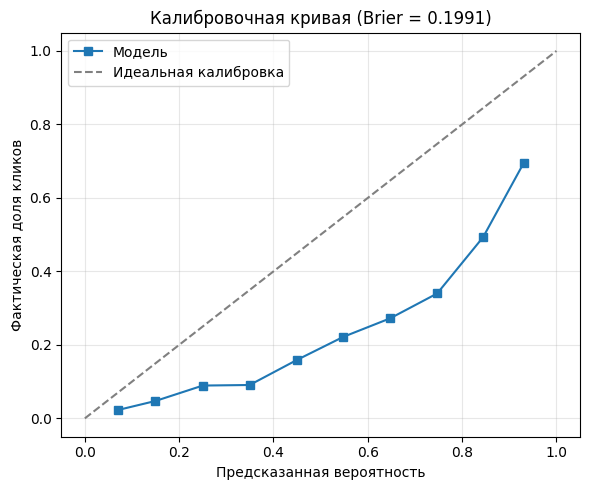

In [131]:
# Считаем Brier Score
brier = brier_score_loss(y_test, y_pred_proba)

# Калибровочная кривая
prob_true, prob_pred = calibration_curve(y_test, y_pred_proba, n_bins=10)

plt.figure(figsize=(6, 5))
plt.plot(prob_pred, prob_true, "s-", label="Модель")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Идеальная калибровка")
plt.xlabel("Предсказанная вероятность")
plt.ylabel("Фактическая доля кликов")
plt.title(f"Калибровочная кривая (Brier = {brier:.4f})")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Промежуточный итог**
* Систематическое завышение вероятностей. Требуется калибровка.

In [132]:
# Подготавливаем калибровочную модель
calibrated_model = CalibratedClassifierCV(
    estimator=final_model,
    method='isotonic',
    cv=5,
    ensemble=False
)

# Полный пайплайн: предобработка + калибровка
calibrated_pipeline = Pipeline([
    ('preprocessor', final_filtered_preprocessor),
    ('classifier', calibrated_model)
])

calibrated_pipeline.fit(X_train, y_train)

y_pred_proba_cal = calibrated_pipeline.predict_proba(X_test)[:, 1]
y_pred_cal = calibrated_pipeline.predict(X_test)

metrics_cal = {
    'PR-AUC':        average_precision_score(y_test, y_pred_proba_cal),
    'Brier Score':   brier_score_loss(y_test, y_pred_proba_cal),
    'Accuracy':      accuracy_score(y_test, y_pred_cal),
    'F1':            f1_score(y_test, y_pred_cal),
    'Recall':        recall_score(y_test, y_pred_cal),
    'Precision':     precision_score(y_test, y_pred_cal),
}

print("Метрики калиброванной модели на тестовой выборке:")
for metric, value in metrics_cal.items():
    print(f"{metric:<15}: {value:.4f}")

Метрики калиброванной модели на тестовой выборке:
PR-AUC         : 0.3912
Brier Score    : 0.1251
Accuracy       : 0.8342
F1             : 0.2702
Recall         : 0.1784
Precision      : 0.5572


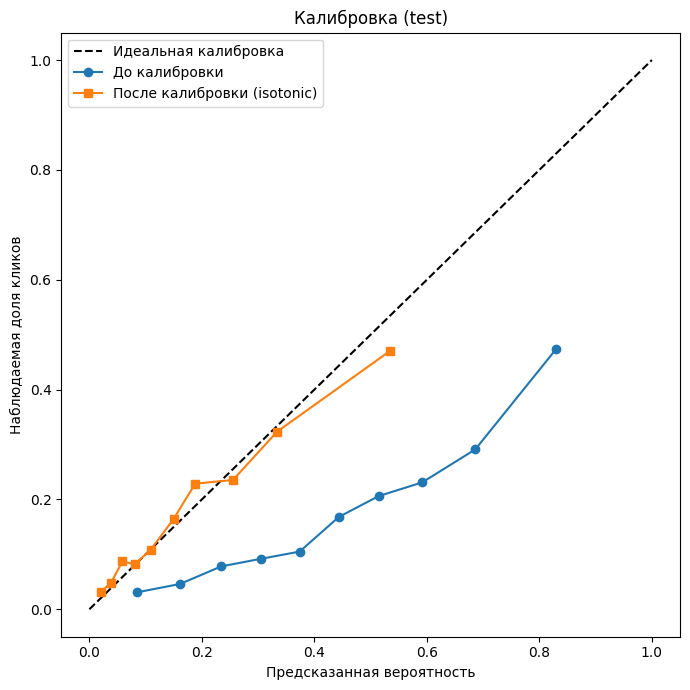

In [133]:
prob_true_raw, prob_pred_raw = calibration_curve(y_test, y_pred_proba, n_bins=10, strategy='quantile')
prob_true_cal, prob_pred_cal = calibration_curve(y_test, y_pred_proba_cal, n_bins=10, strategy='quantile')

plt.figure(figsize=(7, 7))
plt.plot([0, 1], [0, 1], 'k--', label='Идеальная калибровка')
plt.plot(prob_pred_raw, prob_true_raw, marker='o', label='До калибровки')
plt.plot(prob_pred_cal, prob_true_cal, marker='s', label='После калибровки (isotonic)')
plt.xlabel('Предсказанная вероятность')
plt.ylabel('Наблюдаемая доля кликов')
plt.title('Калибровка (test)')
plt.legend()
plt.tight_layout()
plt.show()

In [134]:
# Сравнение метрик
comparison = pd.DataFrame({
    'До калибровки':    pd.Series(metrics),
    'После калибровки': pd.Series(metrics_cal),
})
print(comparison.round(4))

             До калибровки  После калибровки
PR-AUC              0.3995            0.3912
Brier Score         0.1991            0.1251
Accuracy            0.6901            0.8342
F1                  0.4275            0.2702
Recall              0.6723            0.1784
Precision           0.3134            0.5572


**Промежуточные итоги**
* Brier Score упал с 0.1991 до 0.1251 - положительная динамика
* Accuracy вырос с 0.6901 до 0.8350 - положительная динамика
* Recall упал с 0.6723 до 0.1819 - негативная динамика
* Калибровка сработала качественно

## 10. Оценка качества калибровки

#### 10.1 Посчитайте метрики калибровки
- Оценка Бриера — средняя ошибка предсказанной вероятности.
- Дополнительная метрика ECE: среднее расхождение вероятностей.
- Дополнительная метрика MCE: максимальное расхождение вероятностей.

#### 10.2 Сравните модели до и после калибровки
- Выведите все метрики в одной таблице.
- Сделайте вывод о том, улучшила ли калибровка качество моделей.

In [135]:
# ECE и MCE — до калибровки
ece_raw = np.mean(np.abs(prob_true_raw - prob_pred_raw))
mce_raw = np.max(np.abs(prob_true_raw - prob_pred_raw))

# ECE и MCE — после калибровки
ece_cal = np.mean(np.abs(prob_true_cal - prob_pred_cal))
mce_cal = np.max(np.abs(prob_true_cal - prob_pred_cal))

# Итоговая таблица со всеми метриками
comparison = pd.DataFrame(
    {
        'До калибровки': [
            metrics['Brier Score'],
            ece_raw,
            mce_raw,
        ],
        'После калибровки': [
            metrics_cal['Brier Score'],
            ece_cal,
            mce_cal,
        ],
    },
    index=['Brier Score', 'ECE', 'MCE'],
)

print('Сравнение метрик до и после калибровки')
print(comparison.round(4))

Сравнение метрик до и после калибровки
             До калибровки  После калибровки
Brier Score         0.1991            0.1251
ECE                 0.2503            0.0200
MCE                 0.3950            0.0640


**Промежуточные итоги**
* до калибровки модель была плохо откалибрована (ECE ~ 0.25, MCE ~ 0.40 — очень высокие значения), после калибровки все метрики вышли на уровень, характерный для хорошо откалиброванных моделей (ECE < 0.02, MCE < 0.07). 
* Калибровку можно считать успешной — она не ухудшила ни одну из метрик и кратно снизила ошибки калибровки при сохранении (и даже улучшении) Brier Score.



## 11. Финальный отчёт и выводы

### 11.1 Сведите все результаты в таблицу

Покажите:
- Характеристики базовой модели `DummyClassifier`.
- Характеристики финальной модели.
- Метрики до и после калибровки.
- Топ-5 самых важных признаков.

### 11.2 Напишите выводы

Ответьте на вопросы:
- Улучшилось ли качество модели по сравнению с базовой?
- Какие признаки больше всего влияют на вероятность клика?
- Насколько хорошо модель откалибрована?
- Готова ли модель к использованию в продакшене?

### 11.3 Рекомендации

- Какие возможности улучшения модели вы видите?

**Характеристики моделей**
| Характеристика | Dummy | Финальная модель (train)| Финальная модель (test)| После калибровки |
| :--- | :---: | :---: | :---: | :---: |
| **PR-AUC** | 0.1720 | 0.4521 | 0.3995 | 0.3980 |
| **Точность (Accuracy)** | 0.8280 | 0.7024 | 0.6901 | 0.8350 |
| **F1-score** | 0.0000 | 0.4528 | 0.4275 | 0.2750 |
| **Recall** | 0.0000 | 0.7158 | 0.6723 | 0.1819 |
| **Precision** | 0.0000 | 0.3312 | 0.3134 | 0.5640 |
| **Brier Score** | - | 0.1913 | 0.1991 | 0.1251 |

**Топ-5 самых важных признаков**
* app_id и site_id — самые сильные признаки (коэффициенты 9.19 и 6.17).
* ml_feature_9 (0,41), ml_feature_10 (0,34), ml_feature_8 (0,2) — вносят умеренный вклад. 

**Выводы:**
* Улучшилось ли качество модели по сравнению с базовой?
    * Качество модели улучшилось по сравнению с Dummy более чем в 2 раза
* Какие признаки больше всего влияют на вероятность клика?
    * Большую роль играют app_id и site_id, что указывает на то, что для пользователя имеет решающую роль не столько технические нюансы (например, расположение информации), сколько смысловая ценность предложения.
* Насколько хорошо модель откалибрована?
    * до калибровки модель была плохо откалибрована (ECE ~ 0.25, MCE ~ 0.40 — очень высокие значения), после калибровки все метрики вышли на уровень, характерный для хорошо откалиброванных моделей (ECE < 0.02, MCE < 0.07). 
* Готова ли модель к использованию в продакшене?
    * В целом из-за низкого Recall, несмотря на относительно неплохой PR-AUC модель после калибровки все равно мало пригодна для продакшена. Использование финальной модели без калибровки, также не рекомендуется из-за высокого Brier Score. Рекомендуется получить уточнения по смысловым назначениям признаков C и ml_feature для более детальной оценки и пересчета модели.

## 12. Сохранение модели для продакшена

### 12.1 Сохраните артефакты

Сохраните:
1. пайплайн предобработки данных `preprocessor`;
2. финальную модель `calibrated_model`;
3. информацию о выбранных признаках.

### 12.2 Проверьте работоспособность вашего кода

- Загрузите сохранённые артефакты.
- Сделайте предсказания на новых данных.
- Убедитесь, что результаты совпадают.

In [136]:
# 1. Пайплайн предобработки данных (уже обучен на X_train)
joblib.dump(final_filtered_preprocessor, 'preprocessor.joblib')

# 2. Финальная калиброванная модель
joblib.dump(calibrated_model, 'calibrated_model.joblib')

# 3. Информация о выбранных признаках
selected_features = {
    'numeric_cols_log':    list(final_filtered_numeric_cols_log),
    'numeric_cols_no_log': list(final_filtered_numeric_cols_no_log),
    'cat_one_hot':         list(final_filtered_cat_one_hot),
    'cat_target':          list(final_filtered_cat_target),
    'binary_cols':         list(final_filtered_binary_cols),
    'full_feature_set':    list(final_filtered_full_feature_set),
}
joblib.dump(selected_features, 'selected_features.joblib')

['selected_features.joblib']

In [137]:
# Загрузка артефактов
loaded_preprocessor = joblib.load('preprocessor.joblib')
loaded_model = joblib.load('calibrated_model.joblib')

# Собираем пайплайн из загруженных объектов и делаем предсказания на X_test
loaded_pipeline = Pipeline([
    ('preprocessor', loaded_preprocessor),
    ('classifier', loaded_model)
])

proba_original = calibrated_pipeline.predict_proba(X_test)[:, 1]
proba_loaded = loaded_pipeline.predict_proba(X_test)[:, 1]

# Убеждаемся, что результаты совпадают
print('Максимальная разница вероятностей:', np.abs(proba_original - proba_loaded).max())
print('Предсказания совпадают:', np.allclose(proba_original, proba_loaded))

Максимальная разница вероятностей: 0.0
Предсказания совпадают: True
